
# Proyecto Final de Ciencia de Datos

## Clasificación supervisada de tumores de mama mediante algoritmos de aprendizaje automático

### 1. Introducción al proyecto

El presente proyecto tiene como objetivo desarrollar un sistema de clasificación supervisada utilizando algoritmos de aprendizaje automático, con la finalidad de identificar y clasificar tumores de mama como benignos o malignos a partir de características numéricas obtenidas de muestras celulares.

Se utilizará el conjunto de datos Breast Cancer Wisconsin Diagnostic, el cual contiene características relacionadas con la forma, tamaño y comportamiento de los núcleos celulares.

Se implementarán y compararán distintos algoritmos de clasificación, incluyendo Naive Bayes, máquinas de soporte vectorial (SVM), redes neuronales artificiales mediante un perceptrón multicapa (MLP) y regresión logística como modelo de referencia.

El desempeño de los modelos será evaluado mediante métricas estadísticas, validación cruzada y análisis de errores, con el propósito de identificar sus fortalezas, limitaciones y comportamiento en la clasificación de las muestras.

### 2. Objetivo general

Desarrollar, entrenar y evaluar diferentes modelos de aprendizaje automático para realizar la clasificación binaria de tumores de mama, comparando su rendimiento mediante métricas estadísticas y técnicas de validación que permitan identificar el modelo más adecuado para el conjunto de datos analizado.

### 3. Objetivos específicos

- Obtener y describir el conjunto de datos Breast Cancer Wisconsin Diagnostic.
- Realizar un análisis exploratorio de los datos.
- Identificar la distribución de las clases y posibles valores faltantes.
- Aplicar técnicas de preprocesamiento y escalado de variables.
- Implementar modelos Naive Bayes, SVM y redes neuronales MLP.
- Utilizar regresión logística como modelo de referencia.
- Optimizar los hiperparámetros mediante validación cruzada.
- Evaluar y comparar los modelos utilizando diferentes métricas.
- Analizar los errores de clasificación y las limitaciones de los modelos.
- Documentar los resultados de manera reproducible.

### 4. Alcance

El proyecto se enfocará en la clasificación de tumores de mama utilizando datos estructurados y técnicas de aprendizaje automático supervisado. Los resultados obtenidos serán exclusivamente experimentales y académicos, por lo que los modelos no serán considerados herramientas de diagnóstico médico.

In [1]:

import sys
import platform

print("========================================")
print("       PROYECTO CIENCIA DE DATOS")
print("========================================")

print("Python instalado:", sys.version)
print("Sistema operativo:", platform.system())
print("Versión del sistema:", platform.version())
print("========================================")

print("El entorno de Python funciona correctamente.")

       PROYECTO CIENCIA DE DATOS
Python instalado: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Sistema operativo: Windows
Versión del sistema: 10.0.26200
El entorno de Python funciona correctamente.


In [2]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Librerías cargadas correctamente")
print("--------------------------------")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Librerías cargadas correctamente
--------------------------------
Pandas: 3.0.3
NumPy: 2.4.6
Matplotlib: 3.11.0
Seaborn: 0.13.2
Scikit-learn: 1.9.0



# 5. Obtención y descripción del conjunto de datos

## 5.1 Selección del conjunto de datos

Para el desarrollo de este proyecto se seleccionó el conjunto de datos Breast Cancer Wisconsin Diagnostic (WDBC), disponible a través de la biblioteca Scikit-learn. Este conjunto de datos contiene información numérica extraída de imágenes digitalizadas de aspiraciones con aguja fina de masas mamarias.

Las características presentes en el dataset describen diferentes propiedades de los núcleos celulares, tales como el radio, la textura, el perímetro, el área, la suavidad, la compacidad, la concavidad, los puntos cóncavos, la simetría y la dimensión fractal.

El objetivo del conjunto de datos es realizar una clasificación binaria, identificando las muestras como benignas o malignas, a partir de las características numéricas proporcionadas.

Se seleccionó este conjunto de datos debido a que es de acceso público, contiene variables numéricas y permite aplicar diferentes algoritmos de clasificación supervisada sin requerir un proceso complejo de transformación de variables categóricas.

## 5.2 Fuente de los datos

El conjunto de datos será cargado directamente desde la biblioteca Scikit-learn, la cual proporciona una versión estructurada del Breast Cancer Wisconsin Diagnostic Dataset.

La utilización de esta fuente facilita la reproducibilidad del experimento, ya que no será necesario realizar una descarga manual de archivos externos para obtener los datos originales.

In [3]:

# =============================================
# 5.3 IMPORTACIÓN DE LIBRERÍAS PARA EL DATASET
# =============================================

import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [4]:

# =============================================
# 5.4 CARGA DEL CONJUNTO DE DATOS
# =============================================

# Cargar el dataset Breast Cancer Wisconsin Diagnostic
dataset = load_breast_cancer()


print("Dataset cargado correctamente.")
print("Nombre del dataset:", dataset.DESCR.split("\n")[0])

Dataset cargado correctamente.
Nombre del dataset: .. _breast_cancer_dataset:


In [5]:

# =============================================
# 5.5 CONVERSIÓN DE DATOS A DATAFRAME
# =============================================

# Crear un DataFrame con las características del dataset
df = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# Agregar la variable objetivo
df["diagnosis"] = dataset.target

# Mostrar los primeros 5 registros
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:

# =============================================
# 5.6 DIMENSIONES DEL CONJUNTO DE DATOS
# =============================================

# Obtener el número de filas y columnas
filas, columnas = df.shape

print("Dimensiones del dataset")
print("----------------------------")
print("Número de registros:", filas)
print("Número de columnas:", columnas)
print("Número de características:", columnas - 1)

Dimensiones del dataset
----------------------------
Número de registros: 569
Número de columnas: 31
Número de características: 30


In [7]:

# =============================================
# 5.7 IDENTIFICACIÓN DE LAS VARIABLES
# =============================================

# Mostrar los nombres de las variables predictoras
print("Variables predictoras:")
print("--------------------------------")

for i, variable in enumerate(dataset.feature_names, start=1):
    print(f"{i}. {variable}")

print("\nVariable objetivo:")
print("diagnosis")

Variables predictoras:
--------------------------------
1. mean radius
2. mean texture
3. mean perimeter
4. mean area
5. mean smoothness
6. mean compactness
7. mean concavity
8. mean concave points
9. mean symmetry
10. mean fractal dimension
11. radius error
12. texture error
13. perimeter error
14. area error
15. smoothness error
16. compactness error
17. concavity error
18. concave points error
19. symmetry error
20. fractal dimension error
21. worst radius
22. worst texture
23. worst perimeter
24. worst area
25. worst smoothness
26. worst compactness
27. worst concavity
28. worst concave points
29. worst symmetry
30. worst fractal dimension

Variable objetivo:
diagnosis


In [8]:

# =============================================
# 5.8 IDENTIFICACIÓN DE LAS CLASES
# =============================================

# Mostrar las clases originales
print("Clases originales del dataset:")
print(dataset.target_names)

# Mostrar la correspondencia entre números y nombres
for numero, nombre in enumerate(dataset.target_names):
    print(f"Etiqueta {numero} = {nombre}")

Clases originales del dataset:
['malignant' 'benign']
Etiqueta 0 = malignant
Etiqueta 1 = benign


In [9]:

# =============================================
# 5.9 REVISIÓN DE LOS TIPOS DE DATOS
# =============================================

# Mostrar información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [10]:

# =============================================
# 5.10 ESTADÍSTICAS DESCRIPTIVAS
# =============================================

# Obtener estadísticas descriptivas de las variables
estadisticas = df.drop(columns=["diagnosis"]).describe()

estadisticas

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [11]:

# =============================================
# 5.11 IDENTIFICACIÓN DE VALORES FALTANTES
# =============================================

# Contabilizar valores faltantes por columna
valores_faltantes = df.isnull().sum()

# Mostrar únicamente las columnas que tengan valores faltantes
print("Valores faltantes por columna:")
print(valores_faltantes[valores_faltantes > 0])

# Calcular el total de valores faltantes
total_faltantes = df.isnull().sum().sum()

print("\nTotal de valores faltantes:", total_faltantes)

Valores faltantes por columna:
Series([], dtype: int64)

Total de valores faltantes: 0


In [12]:

# =============================================
# 5.12 IDENTIFICACIÓN DE REGISTROS DUPLICADOS
# =============================================

# Contar registros duplicados
duplicados = df.duplicated().sum()

print("Número de registros duplicados:", duplicados)

Número de registros duplicados: 0


In [13]:

# =============================================
# 5.13 DISTRIBUCIÓN DE LAS CLASES
# =============================================

# Contabilizar cada clase
distribucion = df["diagnosis"].value_counts().sort_index()

# Convertir las etiquetas numéricas en nombres
distribucion.index = dataset.target_names

# Calcular porcentajes
porcentajes = (distribucion / len(df)) * 100

# Crear una tabla resumen
tabla_clases = pd.DataFrame({
    "Cantidad": distribucion,
    "Porcentaje": porcentajes
})

print("Distribución de las clases:")
tabla_clases

Distribución de las clases:


,Cantidad,Porcentaje
malignant,212,37.258348
benign,357,62.741652


In [14]:

# =============================================
# 5.14 TABLA DE DESCRIPCIÓN DE LAS VARIABLES
# =============================================

# Crear una tabla con el nombre de las variables y su tipo
descripcion_variables = pd.DataFrame({
    "Variable": df.columns,
    "Tipo de dato": df.dtypes.values,
    "Valores únicos": df.nunique().values
})

descripcion_variables

,Variable,Tipo de dato,Valores únicos
0,mean radius,float64,456
1,mean texture,float64,479
2,mean perimeter,float64,522
3,mean area,float64,539
4,mean smoothness,float64,474
5,mean compactness,float64,537
6,mean concavity,float64,537
7,mean concave points,float64,542
8,mean symmetry,float64,432
9,mean fractal dimension,float64,499



## 5.15 Resultados de la inspección inicial

La inspección inicial del conjunto de datos permitió identificar que el Breast Cancer Wisconsin Diagnostic está conformado por 569 registros y 30 variables predictoras numéricas, además de una variable objetivo denominada diagnosis.

Las variables predictoras describen diferentes características de los núcleos celulares, incluyendo radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal.

La variable objetivo contiene dos categorías: maligno y benigno. En la representación numérica utilizada por Scikit-learn, la etiqueta 0 corresponde a la clase maligna y la etiqueta 1 corresponde a la clase benigna.

La distribución de las clases muestra que existen 212 muestras malignas, equivalentes aproximadamente al 37.26% de los registros, y 357 muestras benignas, correspondientes aproximadamente al 62.74%.

Asimismo, se realizó una inspección de los tipos de datos, valores faltantes y registros duplicados con el propósito de conocer la calidad inicial de la información antes de realizar el análisis exploratorio y el preprocesamiento.

La información obtenida constituye la base para las siguientes etapas del proyecto, en las cuales se analizarán las distribuciones de las variables, sus relaciones y su capacidad para contribuir a la clasificación de las muestras.


# 6. Análisis exploratorio de datos (EDA)

El análisis exploratorio de datos tiene como propósito comprender la estructura, distribución y comportamiento de las variables que conforman el conjunto de datos Breast Cancer Wisconsin Diagnostic.

Mediante técnicas estadísticas y visualizaciones se buscará identificar patrones, relaciones entre características, diferencias entre las clases de diagnóstico y posibles anomalías en los datos.

Este análisis permitirá conocer mejor la información disponible antes de realizar el preprocesamiento y entrenar los modelos de clasificación supervisada.

Se analizará la distribución de las clases, la distribución de las variables numéricas, la presencia de posibles valores atípicos y la correlación entre características. Asimismo, se realizarán comparaciones entre las muestras benignas y malignas para identificar características que puedan contribuir a la diferenciación de ambas clases.

In [15]:

# =============================================
# 6.1 CONFIGURACIÓN GENERAL DE VISUALIZACIONES
# =============================================

# Importar librerías de visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo general
sns.set_theme(style="whitegrid", context="notebook")

# Configurar tamaño predeterminado de las gráficas
plt.rcParams["figure.figsize"] = (10, 6)

# Configurar tamaño de fuente
plt.rcParams["font.size"] = 11

print("Configuración de visualización completada.")

Configuración de visualización completada.


Carpeta de figuras: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\results\figures


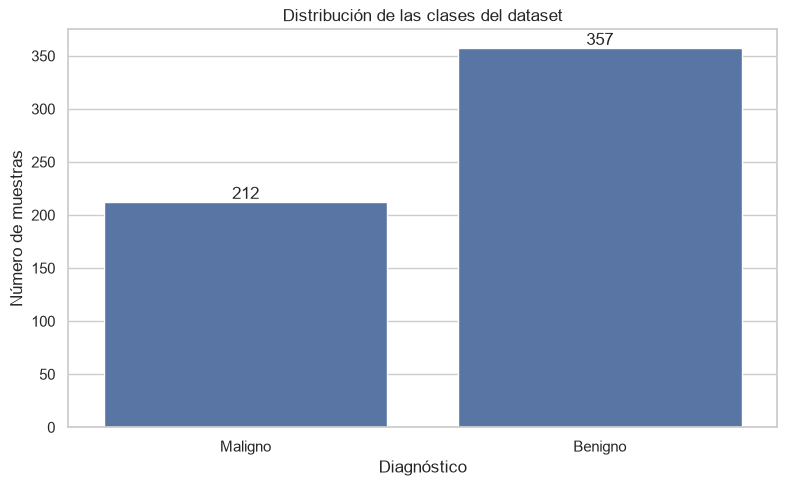

In [16]:

# =============================================
# 6.2 DISTRIBUCIÓN DE LAS CLASES
# =============================================

# Convertir las etiquetas numéricas a nombres
df["diagnosis_name"] = df["diagnosis"].map({
    0: "Maligno",
    1: "Benigno"
})

# Contabilizar las muestras por diagnóstico
conteo_clases = df["diagnosis_name"].value_counts()

# Crear gráfica
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="diagnosis_name",
    order=["Maligno", "Benigno"]
)

# Agregar etiquetas con el número de muestras
for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(
        f"{int(altura)}",
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.title("Distribución de las clases del dataset")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de muestras")

plt.tight_layout()

from pathlib import Path

ruta_figuras = Path.cwd().parent / "results" / "figures"
ruta_figuras.mkdir(parents=True, exist_ok=True)

print("Carpeta de figuras:", ruta_figuras.resolve())
# Guardar figura para el reporte IEEE
plt.savefig(
    ruta_figuras / "01_distribucion_clases.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

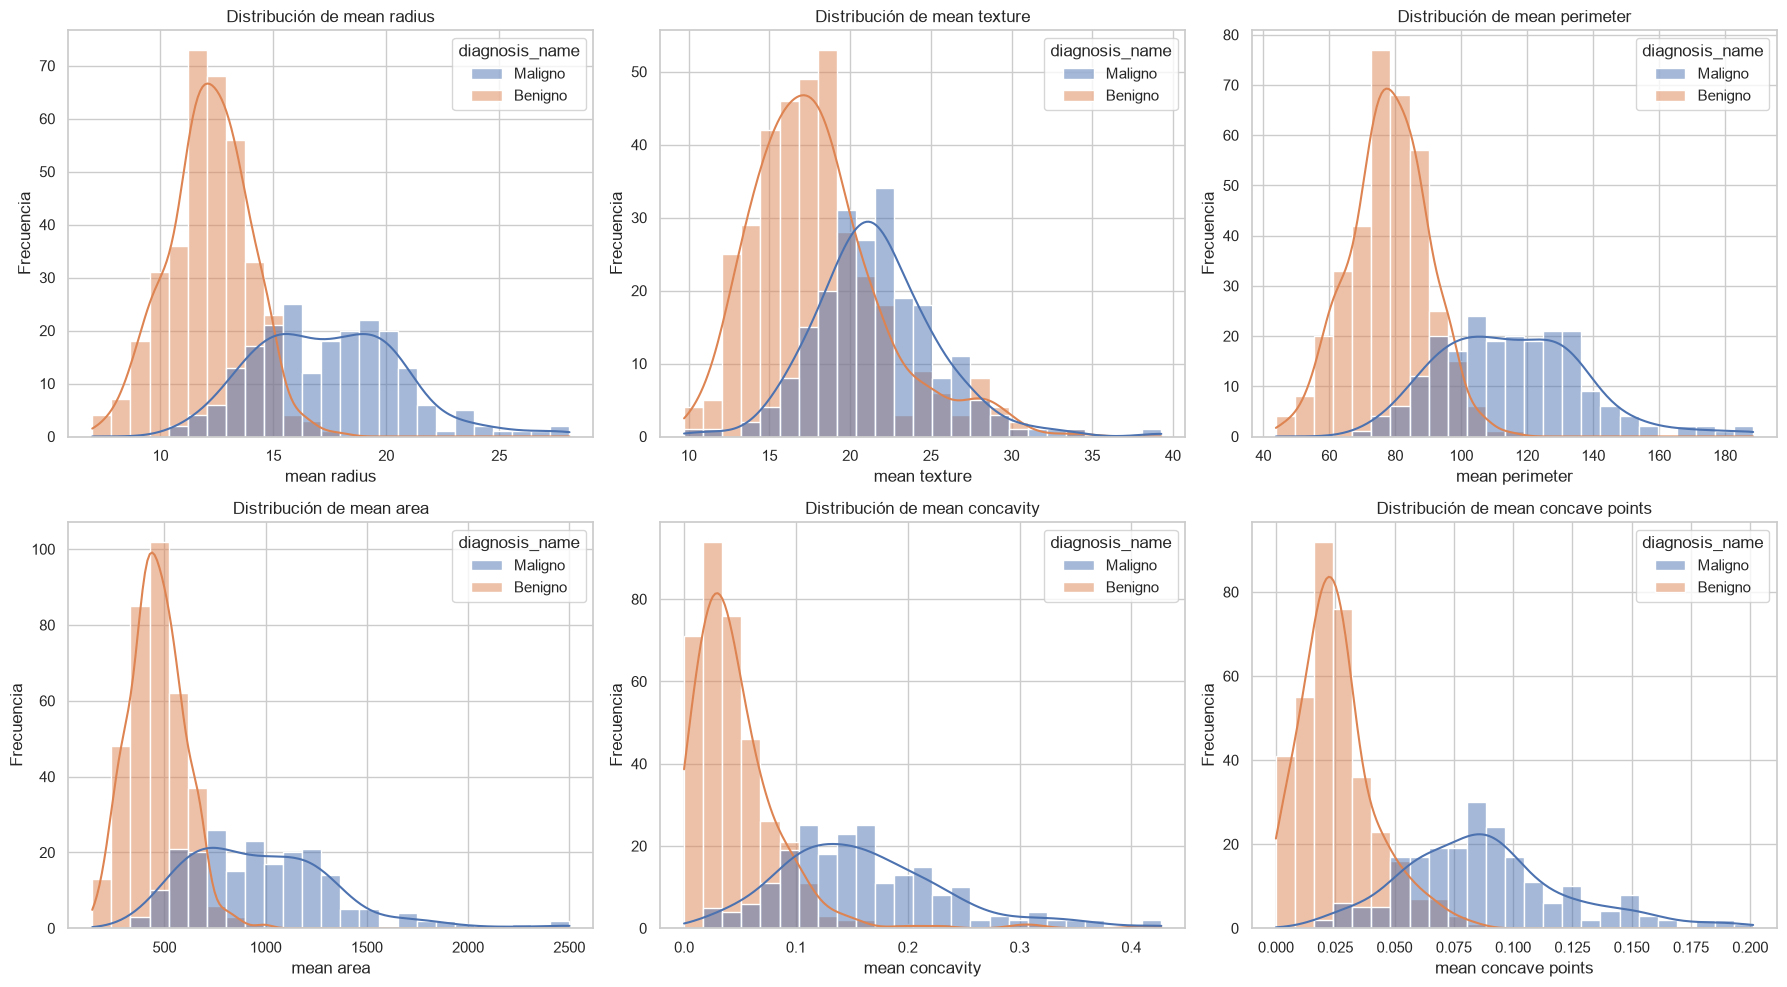

In [17]:

# =============================================
# 6.3 DISTRIBUCIÓN DE VARIABLES NUMÉRICAS
# =============================================

# Seleccionar características para el análisis
variables_histograma = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean concavity",
    "mean concave points"
]

# Crear una figura con seis histogramas
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Convertir los ejes a una lista
axes = axes.flatten()

# Generar histogramas por variable
for i, variable in enumerate(variables_histograma):

    sns.histplot(
        data=df,
        x=variable,
        hue="diagnosis_name",
        kde=True,
        bins=25,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribución de {variable}")
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Frecuencia")

# Ajustar distribución de las gráficas
plt.tight_layout()

# Guardar figura para el reporte IEEE
plt.savefig(
    ruta_figuras / "02_histogramas_variables.png",
    dpi=300,
    bbox_inches="tight"
)

# Mostrar figura
plt.show()

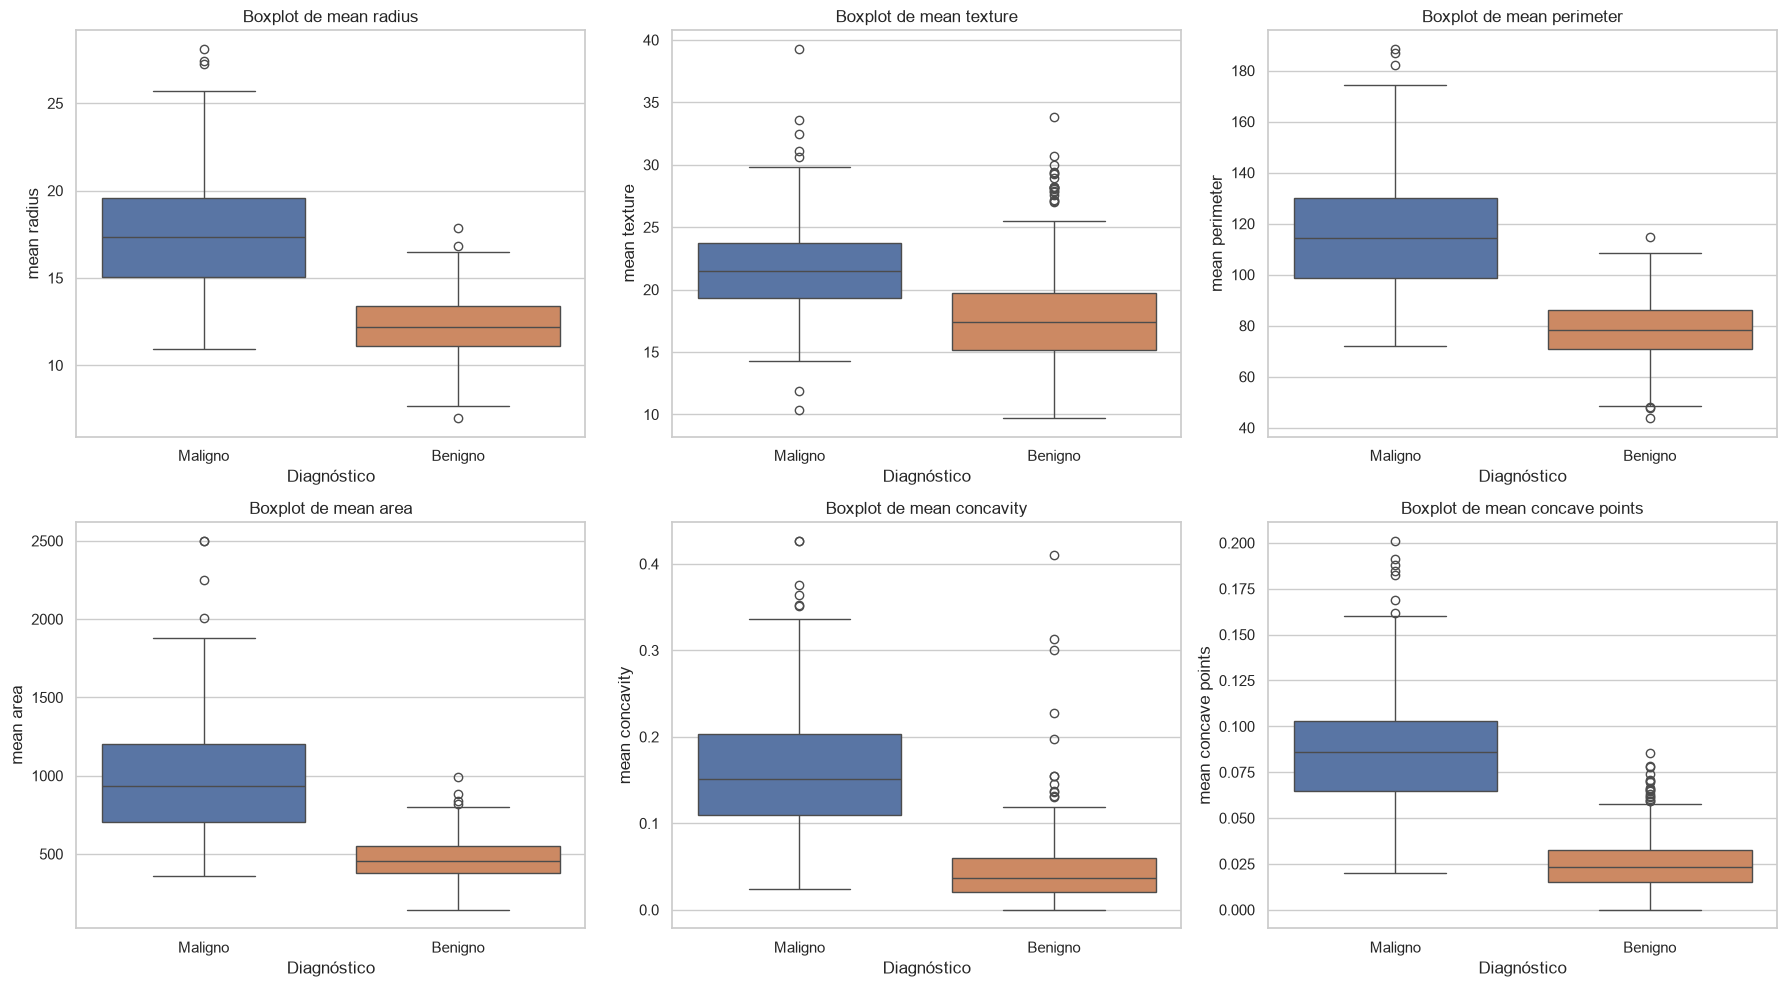

In [18]:

# =============================================
# 6.4 ANÁLISIS DE DISPERSIÓN Y VALORES ATÍPICOS
# =============================================

# Crear figura con seis boxplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, variable in enumerate(variables_histograma):

    sns.boxplot(
        data=df,
        x="diagnosis_name",
        y=variable,
        hue="diagnosis_name",
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot de {variable}")
    axes[i].set_xlabel("Diagnóstico")
    axes[i].set_ylabel(variable)

plt.tight_layout()

# Guardar figura para el reporte IEEE
plt.savefig(
    ruta_figuras / "03_boxplots_variables.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [19]:

# =============================================
# 6.5 SELECCIÓN DE VARIABLES PARA CORRELACIÓN
# =============================================

# Seleccionar variables representativas
variables_correlacion = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean concave points",
    "mean symmetry",
    "mean fractal dimension"
]

# Crear una matriz de correlación
matriz_correlacion = df[variables_correlacion].corr()

# Mostrar la matriz
matriz_correlacion

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
mean radius,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631
mean texture,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437
mean perimeter,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477
mean area,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110
mean smoothness,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792
mean compactness,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369
mean concavity,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783
mean concave points,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917
mean symmetry,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921
mean fractal dimension,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000


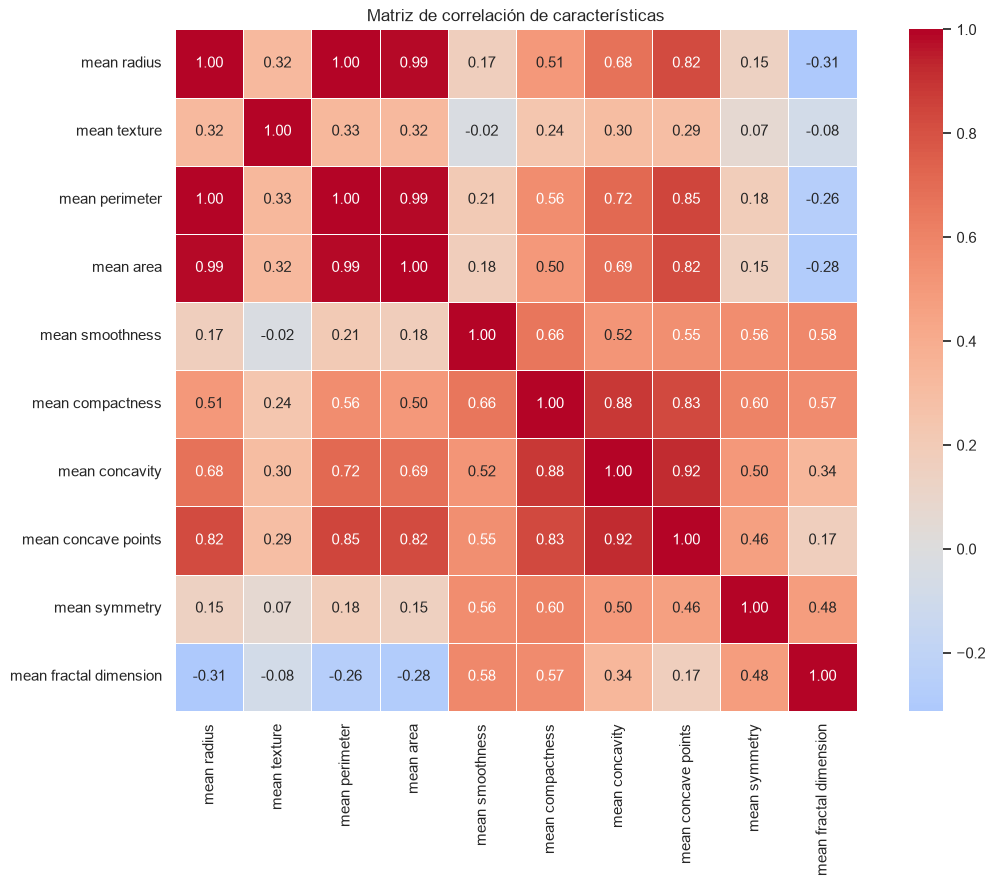

In [20]:

# =============================================
# 6.6 VISUALIZACIÓN DE LA MATRIZ DE CORRELACIÓN
# =============================================

plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Matriz de correlación de características")
plt.tight_layout()

# Guardar figura para el reporte IEEE
plt.savefig(
    ruta_figuras / "04_matriz_correlacion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

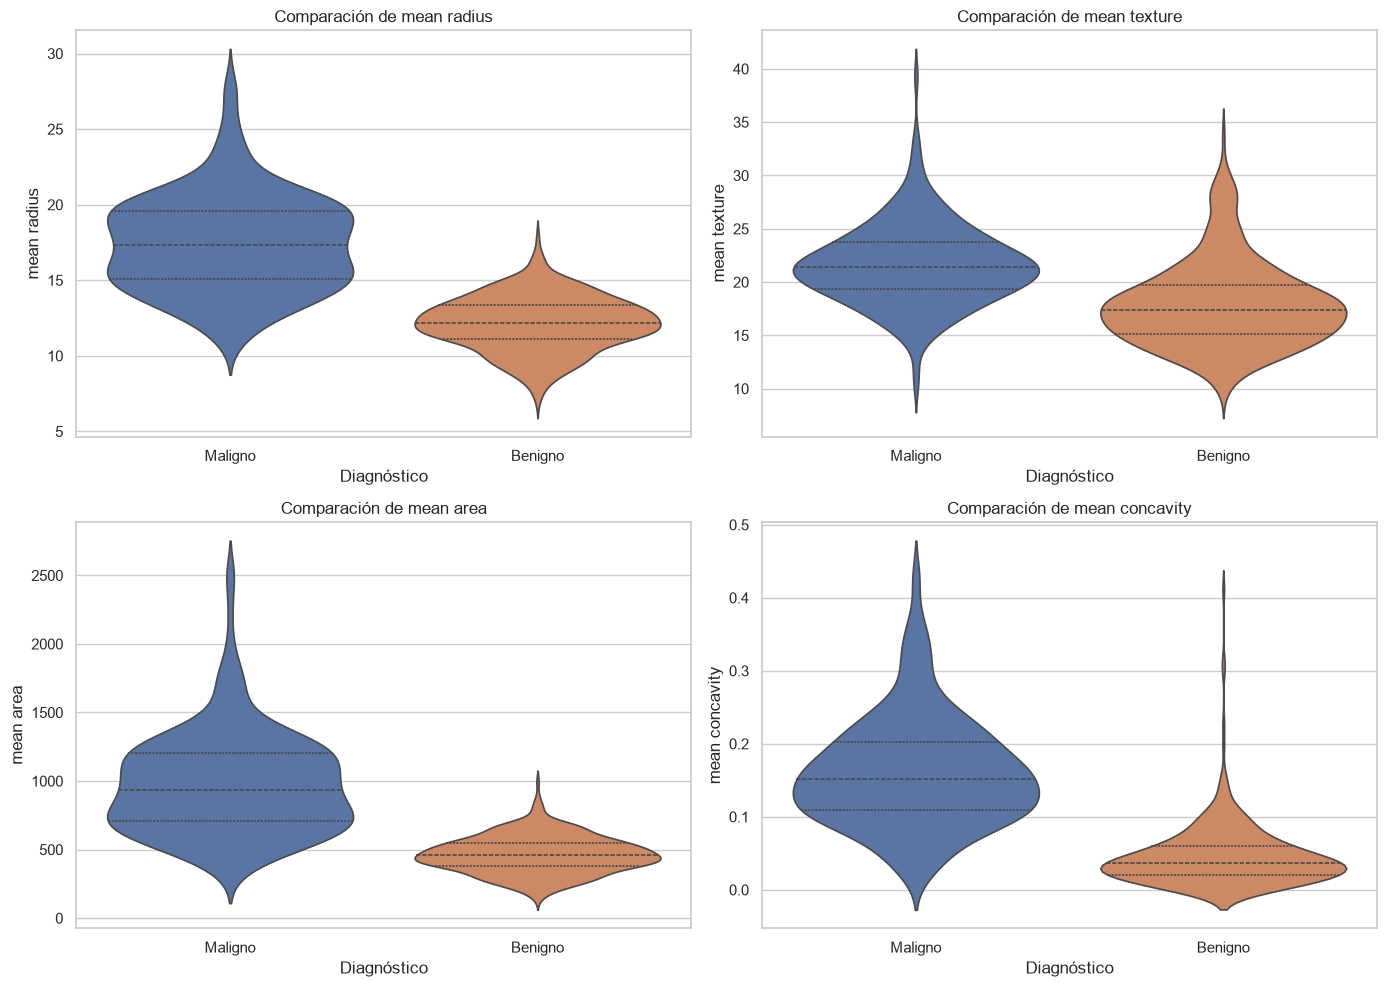

In [21]:

# =============================================
# 6.7 COMPARACIÓN DE CARACTERÍSTICAS POR CLASE
# =============================================

variables_comparacion = [
    "mean radius",
    "mean texture",
    "mean area",
    "mean concavity"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

for i, variable in enumerate(variables_comparacion):

    sns.violinplot(
        data=df,
        x="diagnosis_name",
        y=variable,
        hue="diagnosis_name",
        legend=False,
        inner="quart",
        ax=axes[i]
    )

    axes[i].set_title(f"Comparación de {variable}")
    axes[i].set_xlabel("Diagnóstico")
    axes[i].set_ylabel(variable)

plt.tight_layout()

# Guardar figura para el reporte IEEE
plt.savefig(
    ruta_figuras / "05_comparacion_clases_violin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [22]:

# =============================================
# 6.8 CORRELACIÓN DE LAS VARIABLES CON DIAGNÓSTICO
# =============================================

# Calcular correlación de cada variable con el diagnóstico
correlaciones_diagnostico = (
    df.drop(columns=["diagnosis_name"])
      .corr()["diagnosis"]
      .drop("diagnosis")
)

# Ordenar las correlaciones de menor a mayor
correlaciones_ordenadas = correlaciones_diagnostico.sort_values()

# Mostrar las 10 correlaciones negativas más fuertes
print("Variables con mayor correlación negativa:")
display(correlaciones_ordenadas.head(10))

print("\nVariables con mayor correlación positiva:")
display(correlaciones_ordenadas.tail(10))

Variables con mayor correlación negativa:


worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
worst area             -0.733825
mean radius            -0.730029
mean area              -0.708984
mean concavity         -0.696360
worst concavity        -0.659610
Name: diagnosis, dtype: float64


Variables con mayor correlación positiva:


mean smoothness           -0.358560
mean symmetry             -0.330499
worst fractal dimension   -0.323872
compactness error         -0.292999
concavity error           -0.253730
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: diagnosis, dtype: float64

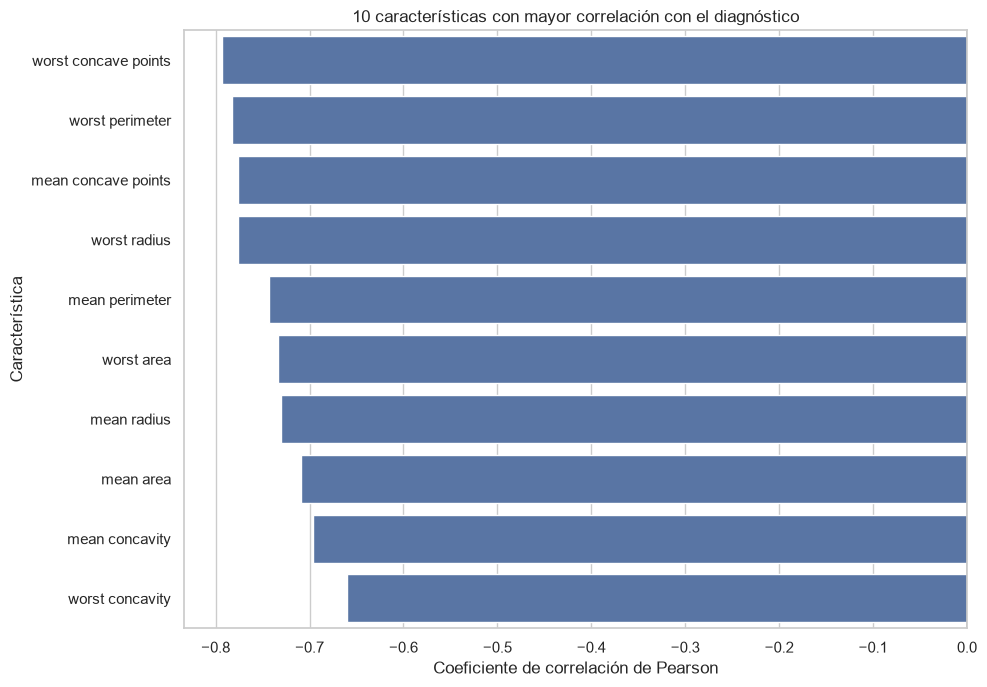

In [23]:

# =============================================
# 6.9 VISUALIZACIÓN DE CORRELACIONES CON DIAGNÓSTICO
# =============================================

# Seleccionar las 10 correlaciones más fuertes en magnitud
top_correlaciones = (
    correlaciones_diagnostico
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

# Recuperar los valores originales
datos_top_correlaciones = correlaciones_diagnostico.loc[top_correlaciones]

# Ordenar para visualizar
datos_top_correlaciones = datos_top_correlaciones.sort_values()

plt.figure(figsize=(10, 7))

sns.barplot(
    x=datos_top_correlaciones.values,
    y=datos_top_correlaciones.index
)

plt.title("10 características con mayor correlación con el diagnóstico")
plt.xlabel("Coeficiente de correlación de Pearson")
plt.ylabel("Característica")
plt.axvline(0, color="black", linewidth=1)

plt.tight_layout()

# Guardar figura para el reporte IEEE
plt.savefig(
    ruta_figuras / "06_correlaciones_diagnostico.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:

# =============================================
# 6.10 CONFIGURACIÓN DE GUARDADO DE FIGURAS
# =============================================

from pathlib import Path

# Ruta de la carpeta donde se guardarán las figuras
ruta_figuras = Path("../results/figures")

# Crear la carpeta si no existe
ruta_figuras.mkdir(parents=True, exist_ok=True)

print("Carpeta de figuras:", ruta_figuras.resolve())
print("La carpeta está lista para guardar resultados.")

Carpeta de figuras: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\results\figures
La carpeta está lista para guardar resultados.



## 6.11 Conclusiones del análisis exploratorio

El análisis exploratorio de datos permitió conocer la estructura y el comportamiento del conjunto de datos Breast Cancer Wisconsin Diagnostic, así como identificar diferencias en la distribución de las características entre las muestras benignas y malignas.

La distribución de las clases mostró que el conjunto de datos contiene una mayor cantidad de muestras benignas que malignas. Aunque existe una diferencia entre ambas categorías, se analizará su impacto durante el entrenamiento y evaluación de los modelos de clasificación.

Mediante los histogramas y diagramas de caja se examinó la distribución de las variables numéricas, su dispersión y la presencia de posibles valores atípicos. Estas visualizaciones permiten comprender las características de los datos y detectar variables que presentan comportamientos diferentes entre los grupos de diagnóstico.

El análisis de correlación permitió identificar relaciones lineales entre algunas características, lo que proporciona información sobre la redundancia potencial de variables y su comportamiento conjunto.

Finalmente, la comparación gráfica entre tumores benignos y malignos permitirá orientar el análisis hacia características que podrían contribuir a la clasificación. Sin embargo, la relevancia definitiva de estas variables deberá comprobarse mediante el entrenamiento, validación y evaluación de los modelos de aprendizaje automático.

Los resultados de esta etapa servirán como base para realizar el preprocesamiento de los datos y establecer un procedimiento de entrenamiento reproducible que permita comparar de manera objetiva los algoritmos seleccionados.

### 6.12 Interpretación de la matriz de correlación

La matriz de correlación permitió identificar relaciones lineales importantes entre diferentes características del conjunto de datos. Se observó una correlación positiva muy elevada entre el radio promedio, el perímetro promedio y el área promedio, con valores aproximados de 1.00, 0.99 y 0.99, respectivamente. Estas relaciones indican que las características asociadas al tamaño de los núcleos celulares presentan un comportamiento estrechamente relacionado.

Asimismo, se identificó una correlación de 0.92 entre la concavidad promedio y los puntos cóncavos promedio, lo que indica una asociación lineal positiva muy fuerte. También se observaron relaciones importantes entre la compacidad, la concavidad y los puntos cóncavos.

Por otra parte, la correlación entre textura promedio y suavidad promedio fue cercana a cero (-0.02), lo que indica que no existe una relación lineal importante entre ambas variables dentro de los datos analizados.

Estos resultados permiten identificar grupos de características que contienen información relacionada y proporcionan una referencia para el análisis y la preparación posterior de las variables.

### 6.13 Interpretación de las distribuciones de las características

Los histogramas permitieron comparar la distribución de seis características entre las muestras benignas y malignas. Se observaron diferencias considerables en el radio promedio, perímetro promedio y área promedio, donde las muestras malignas tendieron a presentar valores superiores a los de las muestras benignas.

También se identificaron diferencias en la concavidad promedio y los puntos cóncavos promedio, cuyas distribuciones mostraron una mayor concentración de valores elevados en las muestras malignas. La textura promedio presentó diferencias entre los grupos, aunque se observó una superposición más considerable de sus distribuciones.

En general, las características relacionadas con el tamaño y la forma de los núcleos celulares muestran diferencias visuales entre ambas categorías de diagnóstico. Estos resultados sugieren que algunas variables podrían proporcionar información útil para los modelos de clasificación, aunque su relevancia deberá comprobarse mediante la evaluación experimental de los algoritmos.

### 6.14 Conclusión del análisis de correlación y distribución

A partir de los resultados obtenidos, se identificaron relaciones lineales fuertes entre algunas características del conjunto de datos, particularmente aquellas relacionadas con el tamaño y la forma de los núcleos celulares.

La comparación de las distribuciones mostró diferencias entre las muestras benignas y malignas, principalmente en las características relacionadas con el radio, el perímetro, el área, la concavidad y los puntos cóncavos.

Estos hallazgos permiten comprender mejor la estructura del conjunto de datos y proporcionan una base para las siguientes etapas del proyecto. No obstante, las relaciones observadas no implican causalidad ni garantizan la capacidad predictiva de una variable individual, por lo que será necesario evaluar su comportamiento mediante modelos de aprendizaje automático.



# 7. Preprocesamiento y preparación de los datos

El preprocesamiento de datos es una etapa fundamental dentro de un proyecto de aprendizaje automático, ya que permite organizar y transformar la información para que los algoritmos puedan trabajar de manera adecuada.

En esta etapa se preparará el conjunto de datos Breast Cancer Wisconsin Diagnostic mediante la separación de las variables predictoras y la variable objetivo, la división de los registros en conjuntos de entrenamiento y prueba, y la estandarización de las características numéricas.

El procedimiento se realizará procurando evitar la fuga de información (data leakage), asegurando que las transformaciones utilizadas durante el entrenamiento no incorporen información procedente del conjunto de prueba.

La preparación de los datos permitirá establecer una base reproducible para el entrenamiento y la comparación de los algoritmos de clasificación que se utilizarán posteriormente.

In [25]:

# =============================================
# 7.1 SEPARACIÓN DE VARIABLES PREDICTORAS Y OBJETIVO
# =============================================

# Definir las variables predictoras
X = df.drop(columns=["diagnosis", "diagnosis_name"])

# Definir la variable objetivo
y = df["diagnosis"]

# Mostrar dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

Dimensiones de X: (569, 30)
Dimensiones de y: (569,)

Variables predictoras:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Distribución de la variable objetivo:
diagnosis
1    357
0    212
Name: count, dtype: int64


In [26]:

# =============================================
# 7.2 IMPORTACIÓN PARA DIVISIÓN DE DATOS
# =============================================

from sklearn.model_selection import train_test_split

print("Función train_test_split importada correctamente.")

Función train_test_split importada correctamente.


In [27]:

# =============================================
# 7.3 DIVISIÓN EN ENTRENAMIENTO Y PRUEBA
# =============================================

# Dividir el dataset en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("División de datos realizada correctamente.")

División de datos realizada correctamente.


In [28]:

# =============================================
# 7.4 VERIFICACIÓN DE LA DIVISIÓN DE DATOS
# =============================================

print("Tamaño de los conjuntos")
print("----------------------------")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nPorcentaje de entrenamiento:")
print(f"{len(X_train) / len(X) * 100:.2f}%")

print("\nPorcentaje de prueba:")
print(f"{len(X_test) / len(X) * 100:.2f}%")

Tamaño de los conjuntos
----------------------------
X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)

Porcentaje de entrenamiento:
79.96%

Porcentaje de prueba:
20.04%


In [29]:

# =============================================
# 7.5 VERIFICACIÓN DE LA DISTRIBUCIÓN DE CLASES
# =============================================

# Calcular proporciones en cada conjunto
distribucion_original = y.value_counts(normalize=True) * 100
distribucion_train = y_train.value_counts(normalize=True) * 100
distribucion_test = y_test.value_counts(normalize=True) * 100

# Crear tabla comparativa
tabla_distribucion = pd.DataFrame({
    "Dataset original (%)": distribucion_original,
    "Entrenamiento (%)": distribucion_train,
    "Prueba (%)": distribucion_test
})

# Cambiar etiquetas de las clases
tabla_distribucion.index = ["Maligno (0)", "Benigno (1)"]

# Mostrar tabla
tabla_distribucion.round(2)

,Dataset original (%),Entrenamiento (%),Prueba (%)
Maligno (0),62.74,62.64,63.16
Benigno (1),37.26,37.36,36.84


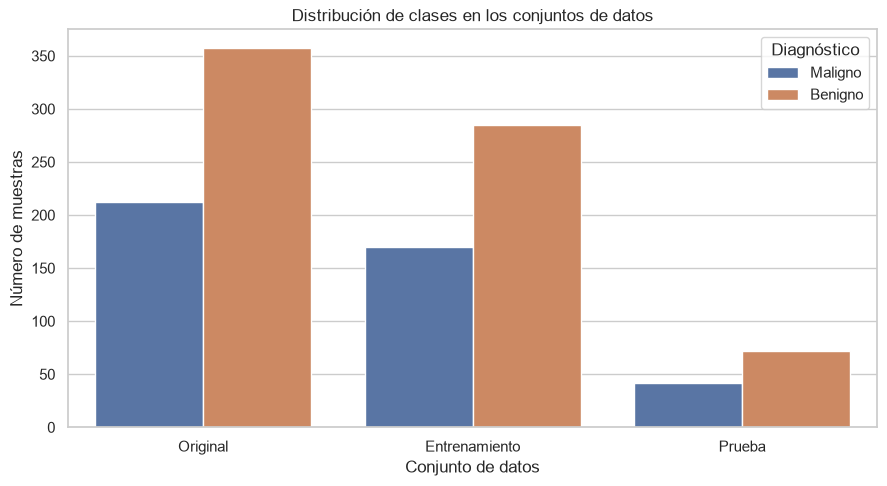

In [30]:

# =============================================
# 7.6 VISUALIZACIÓN DE LA DISTRIBUCIÓN POR CONJUNTO
# =============================================

# Preparar la información
comparacion_clases = pd.DataFrame({
    "Original": y.map({0: "Maligno", 1: "Benigno"}),
    "Entrenamiento": y_train.map({0: "Maligno", 1: "Benigno"}),
    "Prueba": y_test.map({0: "Maligno", 1: "Benigno"})
})

# Convertir la información a formato largo
comparacion_larga = comparacion_clases.melt(
    var_name="Conjunto",
    value_name="Diagnóstico"
)

# Crear gráfica
plt.figure(figsize=(9, 5))

sns.countplot(
    data=comparacion_larga,
    x="Conjunto",
    hue="Diagnóstico"
)

plt.title("Distribución de clases en los conjuntos de datos")
plt.xlabel("Conjunto de datos")
plt.ylabel("Número de muestras")

plt.tight_layout()
plt.show()

In [31]:

# =============================================
# 7.7 IMPORTACIÓN DEL ESTANDARIZADOR
# =============================================

from sklearn.preprocessing import StandardScaler

print("StandardScaler importado correctamente.")

StandardScaler importado correctamente.


In [32]:

# =============================================
# 7.8 CREACIÓN DEL ESTANDARIZADOR
# =============================================

# Crear el objeto StandardScaler
scaler = StandardScaler()

print("Estandarizador creado correctamente.")

Estandarizador creado correctamente.


In [33]:

# =============================================
# 7.9 AJUSTE DEL ESTANDARIZADOR
# =============================================

# Aprender parámetros únicamente del conjunto de entrenamiento
scaler.fit(X_train)

print("Estandarizador ajustado con los datos de entrenamiento.")

Estandarizador ajustado con los datos de entrenamiento.


In [34]:

# =============================================
# 7.10 ESTANDARIZACIÓN DE DATOS DE ENTRENAMIENTO
# =============================================

# Transformar el conjunto de entrenamiento
X_train_scaled = scaler.transform(X_train)

print("Datos de entrenamiento estandarizados.")
print("Dimensiones:", X_train_scaled.shape)

Datos de entrenamiento estandarizados.
Dimensiones: (455, 30)


In [35]:

# =============================================
# 7.11 ESTANDARIZACIÓN DE DATOS DE PRUEBA
# =============================================

# Aplicar los mismos parámetros aprendidos del entrenamiento
X_test_scaled = scaler.transform(X_test)

print("Datos de prueba estandarizados.")
print("Dimensiones:", X_test_scaled.shape)

Datos de prueba estandarizados.
Dimensiones: (114, 30)


In [36]:

# =============================================
# 7.12 VERIFICACIÓN DE LA ESTANDARIZACIÓN
# =============================================

# Calcular medias del entrenamiento estandarizado
medias_train = X_train_scaled.mean(axis=0)

# Calcular desviaciones estándar del entrenamiento
desviaciones_train = X_train_scaled.std(axis=0)

print("Media aproximada de X_train_scaled:")
print(np.round(medias_train.mean(), 6))

print("\nDesviación estándar promedio de X_train_scaled:")
print(np.round(desviaciones_train.mean(), 6))

Media aproximada de X_train_scaled:
0.0

Desviación estándar promedio de X_train_scaled:
1.0


In [37]:

# =============================================
# 7.13 VISUALIZACIÓN DE DATOS ESTANDARIZADOS
# =============================================

# Convertir los datos estandarizados a DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

# Mostrar los primeros cinco registros
X_train_scaled_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
546,-1.072001,-0.658425,-1.088080,-0.939274,-0.135940,-1.008718,-0.968359,-1.102032,0.281062,-0.113231,...,-1.034094,-0.623497,-1.070773,-0.876534,-0.169982,-1.038836,-1.078995,-1.350527,-0.352658,-0.541380
432,1.748743,0.066502,1.751157,1.745559,1.274468,0.842288,1.519852,1.994664,-0.293045,-0.320180,...,1.228342,-0.092833,1.187467,1.104386,1.517001,0.249655,1.178594,1.549916,0.191078,-0.173739
174,-0.974734,-0.931124,-0.997709,-0.867589,-0.613515,-1.138154,-1.092292,-1.243358,0.434395,-0.429247,...,-0.973231,-1.036772,-1.008044,-0.834168,-1.097823,-1.167260,-1.282241,-1.707442,-0.307734,-1.213033
221,-0.145103,-1.215186,-0.123013,-0.253192,0.664482,0.286762,-0.129729,-0.098605,0.555635,0.029395,...,-0.251266,-1.369643,-0.166633,-0.330292,0.234006,0.096874,-0.087521,-0.344838,0.242198,-0.118266
289,-0.771617,-0.081211,-0.803700,-0.732927,-0.672282,-1.006099,-0.798502,-0.684484,0.737495,-0.457213,...,-0.801135,0.079230,-0.824381,-0.741830,-0.911367,-0.984612,-0.933190,-0.777604,0.555118,-0.761639


In [38]:

# =============================================
# 7.14 VERIFICACIÓN FINAL DEL PREPROCESAMIENTO
# =============================================

print("======================================")
print("RESUMEN DEL PREPROCESAMIENTO")
print("======================================")

print("\nDatos originales:")
print("X:", X.shape)
print("y:", y.shape)

print("\nDatos de entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_train_scaled:", X_train_scaled.shape)

print("\nDatos de prueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("X_test_scaled:", X_test_scaled.shape)

print("\nValores faltantes en entrenamiento:")
print(pd.isnull(X_train_scaled).sum())

print("\nValores faltantes en prueba:")
print(pd.isnull(X_test_scaled).sum())

print("\nPreprocesamiento finalizado correctamente.")

RESUMEN DEL PREPROCESAMIENTO

Datos originales:
X: (569, 30)
y: (569,)

Datos de entrenamiento:
X_train: (455, 30)
y_train: (455,)
X_train_scaled: (455, 30)

Datos de prueba:
X_test: (114, 30)
y_test: (114,)
X_test_scaled: (114, 30)

Valores faltantes en entrenamiento:
0

Valores faltantes en prueba:
0

Preprocesamiento finalizado correctamente.


## 7.15 Resultados del preprocesamiento

Durante la etapa de preprocesamiento se preparó el conjunto de datos Breast Cancer Wisconsin Diagnostic para su utilización en algoritmos de aprendizaje automático supervisado.

Inicialmente, se separaron las 30 características numéricas que conforman las variables predictoras y la variable objetivo correspondiente al diagnóstico. Posteriormente, el conjunto de datos fue dividido en 80% para entrenamiento y 20% para prueba, utilizando una semilla de aleatoriedad fija y estratificación para conservar una distribución de las clases similar a la original.

La división generó 455 registros de entrenamiento y 114 registros de prueba. La estratificación permitió conservar una proporción semejante de muestras benignas y malignas en ambos subconjuntos.

Asimismo, se aplicó la técnica de estandarización mediante StandardScaler, con el propósito de transformar las características numéricas y facilitar su utilización en algoritmos sensibles a las diferencias de escala.

El estandarizador fue ajustado exclusivamente con los datos de entrenamiento y posteriormente aplicado tanto al conjunto de entrenamiento como al conjunto de prueba. Este procedimiento permite prevenir la fuga de información y mantener la independencia de los datos destinados a la evaluación.

Finalmente, se verificaron las dimensiones de los conjuntos de datos, la transformación de las características y la ausencia de valores faltantes en los datos procesados.

Con esta etapa se estableció una estructura de datos reproducible, que permitirá continuar con el entrenamiento, ajuste y evaluación de diferentes algoritmos de clasificación.


In [39]:

# =============================================
# 8. IMPORTACIÓN DE LIBRERÍAS PARA MACHINE LEARNING
# =============================================

# Modelos de clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Preprocesamiento y pipelines
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Validación cruzada
from sklearn.model_selection import StratifiedKFold

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Manejo de modelos
from sklearn.base import clone

# Manejo de tablas
import pandas as pd

# Manejo de cálculos
import numpy as np

print("Librerías para Machine Learning importadas correctamente.")

Librerías para Machine Learning importadas correctamente.


In [40]:

# =============================================
# 8.1 DEFINICIÓN DE MODELOS DE CLASIFICACIÓN
# =============================================

modelos = {

    # 1. Regresión logística
    "Regresion_Logistica": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]),

    # 2. K-Nearest Neighbors
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    # 3. Support Vector Machine
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        ))
    ]),

    # 4. Decision Tree
    "Decision_Tree": DecisionTreeClassifier(
        random_state=42
    ),

    # 5. Random Forest
    "Random_Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    # 6. Naive Bayes
    "Naive_Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", GaussianNB())
    ]),

    # 7. Red neuronal MLP
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=2000,
            random_state=42,
            early_stopping=True
        ))
    ])

}

print("Modelos definidos:", len(modelos))

for nombre in modelos:
    print("-", nombre)

Modelos definidos: 7
- Regresion_Logistica
- KNN
- SVM
- Decision_Tree
- Random_Forest
- Naive_Bayes
- MLP


In [41]:

# =============================================
# 8.2 CONFIGURACIÓN DE VALIDACIÓN CRUZADA
# =============================================

# Configurar validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validación cruzada configurada.")
print("Número de particiones:", cv.get_n_splits())

Validación cruzada configurada.
Número de particiones: 5


In [42]:

# =============================================
# 8.3 ENTRENAMIENTO Y VALIDACIÓN CRUZADA
# =============================================

# Lista donde almacenaremos los resultados
resultados_cv = []

# Iterar sobre los modelos
for nombre, modelo in modelos.items():

    print(f"\nEvaluando modelo: {nombre}")

    # Resultados de cada fold
    resultados_folds = []

    # Iterar sobre las cinco particiones
    for fold, (indices_train, indices_val) in enumerate(
        cv.split(X_train, y_train), start=1
    ):

        # Separar datos del fold
        X_fold_train = X_train.iloc[indices_train]
        X_fold_val = X_train.iloc[indices_val]

        y_fold_train = y_train.iloc[indices_train]
        y_fold_val = y_train.iloc[indices_val]

        # Crear una copia independiente del modelo
        modelo_fold = clone(modelo)

        # Entrenar
        modelo_fold.fit(X_fold_train, y_fold_train)

        # Predicciones
        y_pred = modelo_fold.predict(X_fold_val)

        # Probabilidades de clase
        y_proba = modelo_fold.predict_proba(X_fold_val)

        # Identificar columna de probabilidad de malignidad (clase 0)
        clases_modelo = modelo_fold.classes_ if hasattr(
            modelo_fold, "classes_"
        ) else modelo_fold.named_steps["modelo"].classes_

        indice_maligno = list(clases_modelo).index(0)

        proba_maligno = y_proba[:, indice_maligno]

        # Métricas
        accuracy = accuracy_score(y_fold_val, y_pred)

        precision_maligno = precision_score(
            y_fold_val,
            y_pred,
            pos_label=0,
            zero_division=0
        )

        recall_maligno = recall_score(
            y_fold_val,
            y_pred,
            pos_label=0,
            zero_division=0
        )

        f1_maligno = f1_score(
            y_fold_val,
            y_pred,
            pos_label=0,
            zero_division=0
        )

        # Recall de la clase benign = especificidad
        especificidad = recall_score(
            y_fold_val,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        # ROC-AUC considerando maligno como clase positiva
        auc = roc_auc_score(
            (y_fold_val == 0).astype(int),
            proba_maligno
        )

        # Guardar resultados del fold
        resultados_folds.append({
            "Accuracy": accuracy,
            "Precision_Maligno": precision_maligno,
            "Recall_Maligno": recall_maligno,
            "F1_Maligno": f1_maligno,
            "Especificidad": especificidad,
            "ROC_AUC": auc
        })

        print(f"  Fold {fold} completado.")

    # Convertir resultados a DataFrame
    df_folds = pd.DataFrame(resultados_folds)

    # Calcular promedio y desviación estándar
    promedio = df_folds.mean()
    desviacion = df_folds.std()

    # Guardar resumen del modelo
    resultados_cv.append({
        "Modelo": nombre,
        "Accuracy_Media": promedio["Accuracy"],
        "Accuracy_STD": desviacion["Accuracy"],
        "Precision_Maligno_Media": promedio["Precision_Maligno"],
        "Recall_Maligno_Media": promedio["Recall_Maligno"],
        "F1_Maligno_Media": promedio["F1_Maligno"],
        "Especificidad_Media": promedio["Especificidad"],
        "ROC_AUC_Media": promedio["ROC_AUC"],
        "ROC_AUC_STD": desviacion["ROC_AUC"]
    })

    print(f"Modelo {nombre} terminado.")

print("\nTodos los modelos fueron evaluados.")


Evaluando modelo: Regresion_Logistica
  Fold 1 completado.
  Fold 2 completado.
  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo Regresion_Logistica terminado.

Evaluando modelo: KNN
  Fold 1 completado.
  Fold 2 completado.
  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo KNN terminado.

Evaluando modelo: SVM
  Fold 1 completado.
  Fold 2 completado.


C:\Users\jona_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\jona_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\jona_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo SVM terminado.

Evaluando modelo: Decision_Tree
  Fold 1 completado.


C:\Users\jona_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\jona_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Fold 2 completado.
  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo Decision_Tree terminado.

Evaluando modelo: Random_Forest
  Fold 1 completado.
  Fold 2 completado.
  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo Random_Forest terminado.

Evaluando modelo: Naive_Bayes
  Fold 1 completado.
  Fold 2 completado.
  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo Naive_Bayes terminado.

Evaluando modelo: MLP
  Fold 1 completado.
  Fold 2 completado.
  Fold 3 completado.
  Fold 4 completado.
  Fold 5 completado.
Modelo MLP terminado.

Todos los modelos fueron evaluados.


In [43]:

# =============================================
# 8.4 TABLA COMPARATIVA DE MODELOS
# =============================================

# Convertir resultados a DataFrame
tabla_resultados_cv = pd.DataFrame(resultados_cv)

# Ordenar modelos por Recall de malignos
tabla_resultados_cv = tabla_resultados_cv.sort_values(
    by="Recall_Maligno_Media",
    ascending=False
)

# Mostrar resultados
display(
    tabla_resultados_cv.style.format({
        "Accuracy_Media": "{:.4f}",
        "Accuracy_STD": "{:.4f}",
        "Precision_Maligno_Media": "{:.4f}",
        "Recall_Maligno_Media": "{:.4f}",
        "F1_Maligno_Media": "{:.4f}",
        "Especificidad_Media": "{:.4f}",
        "ROC_AUC_Media": "{:.4f}",
        "ROC_AUC_STD": "{:.4f}"
    })
)

,Modelo,Accuracy_Media,Accuracy_STD,Precision_Maligno_Media,Recall_Maligno_Media,F1_Maligno_Media,Especificidad_Media,ROC_AUC_Media,ROC_AUC_STD
0,Regresion_Logistica,0.9780,0.0110,0.9770,0.9647,0.9703,0.9860,0.9959,0.0055
4,Random_Forest,0.9626,0.0200,0.9440,0.9588,0.9506,0.9649,0.9896,0.0092
2,SVM,0.9692,0.0163,0.9649,0.9529,0.9583,0.9789,0.9956,0.0053
6,MLP,0.9516,0.0265,0.9329,0.9412,0.9359,0.9579,0.9840,0.0105
1,KNN,0.9626,0.0125,0.9707,0.9294,0.9490,0.9825,0.9882,0.0091
3,Decision_Tree,0.9165,0.0200,0.8632,0.9235,0.8919,0.9123,0.9179,0.0225
5,Naive_Bayes,0.9341,0.0320,0.9220,0.9000,0.9106,0.9544,0.9884,0.0084


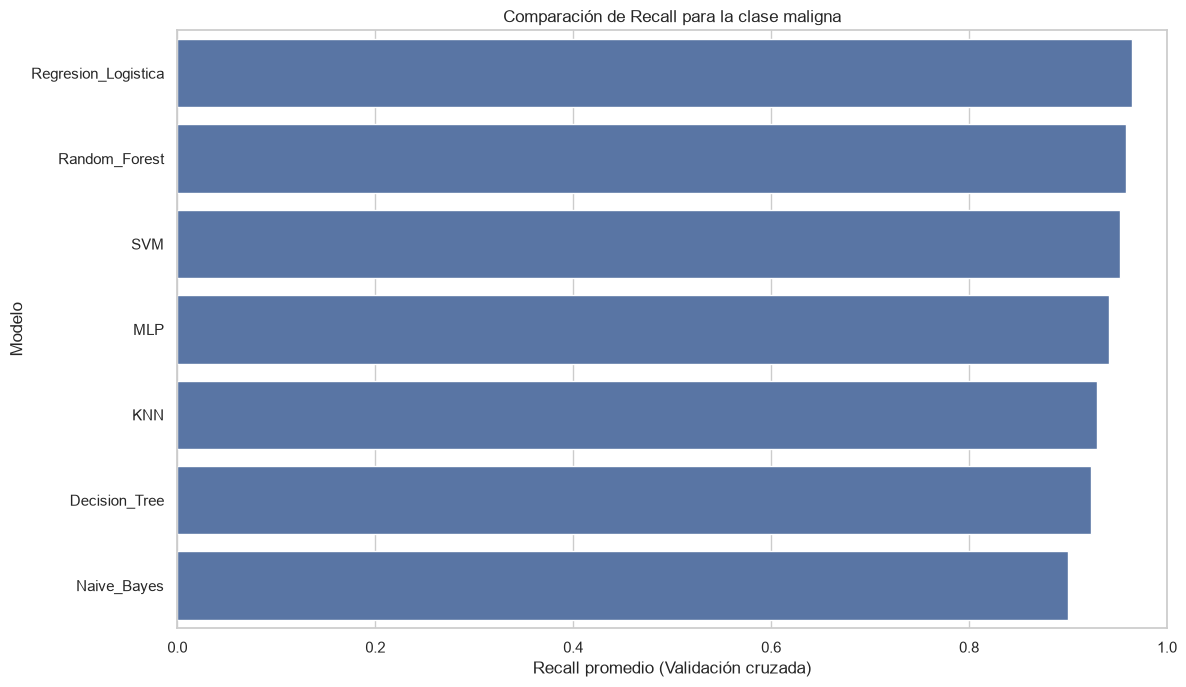

In [44]:

# =============================================
# 8.5 COMPARACIÓN VISUAL DEL RECALL DE MALIGNOS
# =============================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=tabla_resultados_cv,
    x="Recall_Maligno_Media",
    y="Modelo"
)

plt.title("Comparación de Recall para la clase maligna")
plt.xlabel("Recall promedio (Validación cruzada)")
plt.ylabel("Modelo")

plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [45]:

# =============================================
# 8.6 EXPORTACIÓN DE RESULTADOS DE VALIDACIÓN
# =============================================

from pathlib import Path

# Crear carpeta de resultados si no existe
ruta_resultados = Path("../results")
ruta_resultados.mkdir(parents=True, exist_ok=True)

# Definir archivo de salida
archivo_resultados_cv = ruta_resultados / "comparacion_modelos_cv.csv"

# Guardar tabla de resultados
tabla_resultados_cv.to_csv(
    archivo_resultados_cv,
    index=False,
    encoding="utf-8"
)

print("Resultados guardados correctamente.")
print("Archivo:", archivo_resultados_cv.resolve())

Resultados guardados correctamente.
Archivo: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\results\comparacion_modelos_cv.csv


## 8. Entrenamiento y comparación de modelos de aprendizaje automático

En esta etapa se implementaron siete algoritmos de clasificación con el objetivo de evaluar su capacidad para identificar muestras benignas y malignas a partir de las características numéricas del conjunto de datos Breast Cancer Wisconsin Diagnostic.

Los algoritmos utilizados fueron Regresión Logística, K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest, Gaussian Naive Bayes y Multilayer Perceptron.

Para realizar una comparación consistente, se utilizó validación cruzada estratificada de cinco particiones sobre el conjunto de entrenamiento. Este procedimiento permite evaluar cada algoritmo mediante diferentes subconjuntos de entrenamiento y validación, manteniendo una distribución de clases semejante entre las particiones.

Los modelos sensibles a la escala de las variables incorporaron estandarización mediante StandardScaler dentro de pipelines de procesamiento. Esta implementación permite que el escalado se ajuste únicamente con los datos de entrenamiento de cada partición, evitando la fuga de información hacia los datos de validación.

El rendimiento se evaluó mediante Accuracy, Precision, Recall, F1-score, especificidad y ROC-AUC, considerando la clase maligna como clase positiva para las métricas de Precision, Recall y F1-score.

Los resultados de las cinco particiones se resumieron mediante valores promedio y, para algunas métricas, desviación estándar. Esta información permitirá comparar tanto el desempeño de los algoritmos como la consistencia de sus resultados.

El conjunto de prueba se mantuvo separado de este procedimiento y será utilizado posteriormente para realizar la evaluación final del modelo seleccionado.


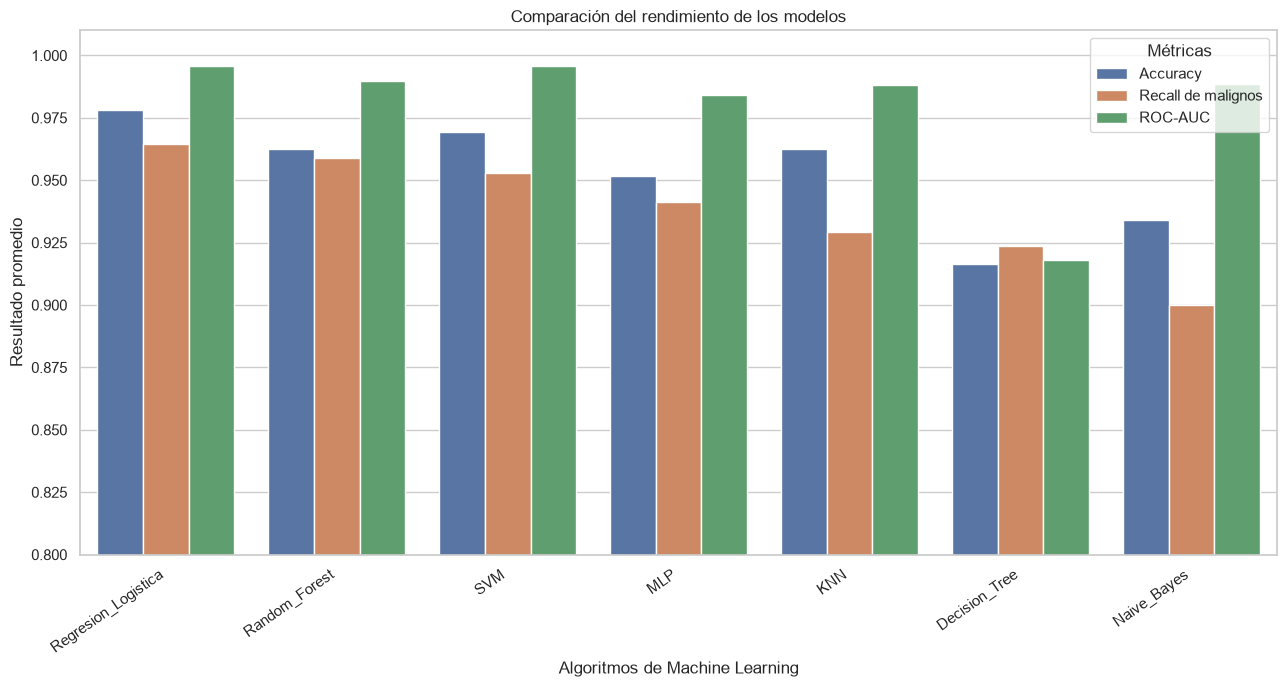

In [46]:

# =============================================
# 8.7 COMPARACIÓN DE LOS SIETE MODELOS
# =============================================

metricas = [
    "Accuracy_Media",
    "Recall_Maligno_Media",
    "ROC_AUC_Media"
]

nombres_metricas = [
    "Accuracy",
    "Recall de malignos",
    "ROC-AUC"
]

tabla_grafica = tabla_resultados_cv.melt(
    id_vars="Modelo",
    value_vars=metricas,
    var_name="Metrica",
    value_name="Resultado"
)

tabla_grafica["Metrica"] = tabla_grafica["Metrica"].map(
    dict(zip(metricas, nombres_metricas))
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=tabla_grafica,
    x="Modelo",
    y="Resultado",
    hue="Metrica"
)

plt.title("Comparación del rendimiento de los modelos")
plt.xlabel("Algoritmos de Machine Learning")
plt.ylabel("Resultado promedio")
plt.ylim(0.80, 1.01)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Métricas")

plt.tight_layout()
plt.show()


## 8.7 Análisis e interpretación de los resultados de validación cruzada

Después de implementar los siete algoritmos de clasificación y realizar su evaluación mediante validación cruzada estratificada de cinco particiones, se obtuvieron resultados que permiten comparar el rendimiento de cada modelo en la identificación de muestras benignas y malignas.

El algoritmo de Regresión Logística presentó el mejor desempeño general, obteniendo un Accuracy promedio de 97.80%, una Precision para la clase maligna de 97.70%, un Recall de 96.47%, un F1-score de 97.03% y un ROC-AUC de 99.59%.

Estos resultados indican que el modelo presentó una elevada capacidad para identificar correctamente las muestras malignas y distinguir entre las dos categorías del conjunto de datos.

Por otra parte, el algoritmo Support Vector Machine obtuvo un Accuracy de 96.92% y un ROC-AUC de 99.56%, mostrando un rendimiento muy cercano al de la Regresión Logística. Random Forest también presentó resultados competitivos, con un Recall de malignos de 95.88%.

En el caso de K-Nearest Neighbors, se obtuvo una Precision de 97.07% para la clase maligna, aunque su Recall fue de 92.94%. Esto demuestra que, pese a presentar una elevada precisión en sus predicciones positivas, su capacidad para identificar todas las muestras malignas fue inferior a la de los primeros modelos.

Los algoritmos Multilayer Perceptron, Gaussian Naive Bayes y Decision Tree presentaron resultados inferiores en términos de Accuracy y Recall respecto a la Regresión Logística.

En conclusión, la Regresión Logística se identifica como la mejor candidata inicial para continuar con el proceso de experimentación, debido a que obtuvo los valores promedio más elevados de Accuracy, Recall de malignos, F1-score y ROC-AUC.

No obstante, esta selección corresponde a los resultados de validación cruzada y deberá confirmarse mediante la optimización y evaluación final utilizando el conjunto de prueba independiente.


In [47]:

# =============================================
# 9. IMPORTACIÓN DE HERRAMIENTAS DE OPTIMIZACIÓN
# =============================================

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np

print("Herramientas de optimización importadas correctamente.")


Herramientas de optimización importadas correctamente.


In [48]:

# =============================================
# 9.1 DEFINICIÓN DEL CRITERIO DE OPTIMIZACIÓN
# =============================================

# Crear métrica personalizada para detectar malignos
scorer_recall_maligno = make_scorer(
    recall_score,
    pos_label=0,
    zero_division=0
)

print("Criterio de optimización configurado.")
print("Métrica principal: Recall de la clase maligna.")


Criterio de optimización configurado.
Métrica principal: Recall de la clase maligna.


In [49]:

# =============================================
# 9.2 OPTIMIZACIÓN DE REGRESIÓN LOGÍSTICA
# =============================================

# Crear pipeline
pipeline_logistica = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Definir combinaciones de hiperparámetros
parametros_logistica = {
    "modelo__C": [0.01, 0.1, 1, 10, 100],
    "modelo__class_weight": [None, "balanced"]
}

# Configurar GridSearchCV
grid_logistica = GridSearchCV(
    estimator=pipeline_logistica,
    param_grid=parametros_logistica,
    scoring=scorer_recall_maligno,
    cv=cv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

# Entrenar y buscar la mejor configuración
grid_logistica.fit(X_train, y_train)

print("\nOPTIMIZACIÓN DE REGRESIÓN LOGÍSTICA")
print("Mejores parámetros:")
print(grid_logistica.best_params_)

print("\nMejor Recall de validación cruzada:")
print(round(grid_logistica.best_score_, 4))


Fitting 5 folds for each of 10 candidates, totalling 50 fits

OPTIMIZACIÓN DE REGRESIÓN LOGÍSTICA
Mejores parámetros:
{'modelo__C': 1, 'modelo__class_weight': 'balanced'}

Mejor Recall de validación cruzada:
0.9765


In [50]:

# =============================================
# 9.3 OPTIMIZACIÓN DE SUPPORT VECTOR MACHINE
# =============================================

from sklearn.calibration import CalibratedClassifierCV

# Pipeline interno: escalado y SVM
pipeline_svm_interno = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", SVC(random_state=42))
])

# Calibración de probabilidades
modelo_svm_calibrado = CalibratedClassifierCV(
    estimator=pipeline_svm_interno,
    method="sigmoid",
    cv=3
)

# Definir combinaciones de hiperparámetros
parametros_svm = [
    {
        "estimator__modelo__kernel": ["rbf"],
        "estimator__modelo__C": [0.1, 1, 10, 100],
        "estimator__modelo__gamma": ["scale", "auto", 0.01]
    },
    {
        "estimator__modelo__kernel": ["linear"],
        "estimator__modelo__C": [0.1, 1, 10, 100]
    }
]

# Configurar GridSearchCV
grid_svm = GridSearchCV(
    estimator=modelo_svm_calibrado,
    param_grid=parametros_svm,
    scoring=scorer_recall_maligno,
    cv=cv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

# Entrenar y buscar la mejor configuración
grid_svm.fit(X_train, y_train)

print("\nOPTIMIZACIÓN DE SVM")
print("Mejores parámetros:")
print(grid_svm.best_params_)

print("\nMejor Recall de validación cruzada:")
print(round(grid_svm.best_score_, 4))


Fitting 5 folds for each of 16 candidates, totalling 80 fits

OPTIMIZACIÓN DE SVM
Mejores parámetros:
{'estimator__modelo__C': 100, 'estimator__modelo__gamma': 'scale', 'estimator__modelo__kernel': 'rbf'}

Mejor Recall de validación cruzada:
0.9647


In [51]:

# =============================================
# 9.4 OPTIMIZACIÓN DE RANDOM FOREST
# =============================================

# Crear modelo base
modelo_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Definir combinaciones de hiperparámetros
parametros_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

# Configurar GridSearchCV
grid_rf = GridSearchCV(
    estimator=modelo_rf,
    param_grid=parametros_rf,
    scoring=scorer_recall_maligno,
    cv=cv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

# Entrenar y buscar la mejor configuración
grid_rf.fit(X_train, y_train)

print("\nOPTIMIZACIÓN DE RANDOM FOREST")
print("Mejores parámetros:")
print(grid_rf.best_params_)

print("\nMejor Recall de validación cruzada:")
print(round(grid_rf.best_score_, 4))


Fitting 5 folds for each of 48 candidates, totalling 240 fits

OPTIMIZACIÓN DE RANDOM FOREST
Mejores parámetros:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Mejor Recall de validación cruzada:
0.9706


In [52]:

# =============================================
# 9.5 COMPARACIÓN DE MODELOS OPTIMIZADOS
# =============================================

# Crear tabla con resultados
resultados_optimizacion = pd.DataFrame([
    {
        "Modelo": "Regresion_Logistica",
        "Recall_Optimizado": grid_logistica.best_score_,
        "Mejores_Parametros": str(grid_logistica.best_params_)
    },
    {
        "Modelo": "SVM",
        "Recall_Optimizado": grid_svm.best_score_,
        "Mejores_Parametros": str(grid_svm.best_params_)
    },
    {
        "Modelo": "Random_Forest",
        "Recall_Optimizado": grid_rf.best_score_,
        "Mejores_Parametros": str(grid_rf.best_params_)
    }
])

# Ordenar por Recall
resultados_optimizacion = resultados_optimizacion.sort_values(
    by="Recall_Optimizado",
    ascending=False
)

# Mostrar resultados
display(
    resultados_optimizacion.style.format({
        "Recall_Optimizado": "{:.4f}"
    })
)


,Modelo,Recall_Optimizado,Mejores_Parametros
0,Regresion_Logistica,0.9765,"{'modelo__C': 1, 'modelo__class_weight': 'balanced'}"
2,Random_Forest,0.9706,"{'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}"
1,SVM,0.9647,"{'estimator__modelo__C': 100, 'estimator__modelo__gamma': 'scale', 'estimator__modelo__kernel': 'rbf'}"


In [53]:

# =============================================
# 9.6 COMPARACIÓN ANTES Y DESPUÉS
# =============================================

# Recuperar Recall de la primera experimentación
recall_original = {
    "Regresion_Logistica": 0.964705882,
    "SVM": 0.952941176,
    "Random_Forest": 0.958823529
}

# Crear comparación
comparacion_optimizacion = pd.DataFrame([
    {
        "Modelo": nombre,
        "Recall_Original": recall_original[nombre],
        "Recall_Optimizado": grid.best_score_,
        "Diferencia": grid.best_score_ - recall_original[nombre]
    }
    for nombre, grid in [
        ("Regresion_Logistica", grid_logistica),
        ("SVM", grid_svm),
        ("Random_Forest", grid_rf)
    ]
])

display(
    comparacion_optimizacion.style.format({
        "Recall_Original": "{:.4f}",
        "Recall_Optimizado": "{:.4f}",
        "Diferencia": "{:+.4f}"
    })
)


,Modelo,Recall_Original,Recall_Optimizado,Diferencia
0,Regresion_Logistica,0.9647,0.9765,+0.0118
1,SVM,0.9529,0.9647,+0.0118
2,Random_Forest,0.9588,0.9706,+0.0118


In [55]:

# =============================================
# 9.7 EXPORTACIÓN DE RESULTADOS OPTIMIZADOS
# =============================================
from pathlib import Path

ruta_resultados = Path.cwd().parent / "results"
ruta_resultados.mkdir(parents=True, exist_ok=True)

# Guardar resultados de optimización
archivo_optimizacion = ruta_resultados / "resultados_optimizacion.csv"

resultados_optimizacion.to_csv(
    archivo_optimizacion,
    index=False,
    encoding="utf-8"
)

# Guardar comparación antes y después
archivo_comparacion = ruta_resultados / "comparacion_antes_despues.csv"

comparacion_optimizacion.to_csv(
    archivo_comparacion,
    index=False,
    encoding="utf-8"
)

print("Resultados de optimización guardados correctamente.")
print("Archivo 1:", archivo_optimizacion.resolve())
print("Archivo 2:", archivo_comparacion.resolve())


Resultados de optimización guardados correctamente.
Archivo 1: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\results\resultados_optimizacion.csv
Archivo 2: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\results\comparacion_antes_despues.csv


## 9. Optimización de hiperparámetros

En esta etapa se realizó la optimización de hiperparámetros de los tres algoritmos que presentaron los resultados más competitivos durante la experimentación inicial: Regresión Logística, Support Vector Machine y Random Forest.

Para llevar a cabo este procedimiento se utilizó la herramienta GridSearchCV de la biblioteca Scikit-learn, la cual permite evaluar diferentes combinaciones de hiperparámetros mediante validación cruzada.

Se estableció como criterio principal de optimización el Recall de la clase maligna, identificada mediante la etiqueta 0 del conjunto de datos. Esta decisión se tomó debido a la importancia de evaluar la capacidad de los modelos para identificar correctamente las muestras malignas.

La búsqueda de hiperparámetros se realizó utilizando cinco particiones de validación cruzada estratificada, exclusivamente sobre el conjunto de entrenamiento. De esta manera, se mantuvo separado el conjunto de prueba para evitar que participara en la selección de las configuraciones.

Para Regresión Logística se evaluaron diferentes valores del parámetro de regularización C y opciones de ponderación de clases. Para Support Vector Machine se analizaron diferentes kernels, valores de C y configuraciones de gamma. Finalmente, para Random Forest se modificaron la cantidad de árboles, profundidad máxima y condiciones de división de los nodos.

Los resultados obtenidos permitieron identificar las configuraciones con mayor Recall promedio para cada algoritmo. Posteriormente, se realizó una comparación entre los resultados originales y los optimizados, con el propósito de determinar si los ajustes produjeron mejoras en la detección de muestras malignas.

La selección definitiva del modelo se realizará considerando también las demás métricas de clasificación y su desempeño sobre el conjunto de prueba independiente.


# 10. Evaluación final de los modelos

En esta etapa se realizará la evaluación final de los modelos de clasificación seleccionados durante el proceso de optimización de hiperparámetros.

Para este procedimiento se utilizará el conjunto de datos de prueba, el cual se mantuvo separado durante las etapas de entrenamiento y optimización.

Se evaluarán los modelos de Regresión Logística, Support Vector Machine (SVM) y Random Forest, utilizando métricas de clasificación que permitan analizar su capacidad para identificar correctamente las muestras benignas y malignas.

La evaluación incluirá Accuracy, Precision, Recall, F1-score, matrices de confusión y curvas ROC, con el propósito de comparar el rendimiento de los modelos y determinar cuál presenta el comportamiento más adecuado para el problema de clasificación.


In [56]:
# 10.1. Definir los modelos optimizados

modelos_optimizados = {
    "Regresión Logística": grid_logistica.best_estimator_,
    "SVM": grid_svm.best_estimator_,
    "Random Forest": grid_rf.best_estimator_
}

print("Modelos optimizados preparados:")
for nombre in modelos_optimizados:
    print("-", nombre)

Modelos optimizados preparados:
- Regresión Logística
- SVM
- Random Forest


In [57]:
resultados_finales = []

for nombre, modelo in modelos_optimizados.items():

    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)

    # Probabilidad de la clase maligna (0)
    indice_maligno = list(modelo.classes_).index(0)
    prob_maligno = y_prob[:, indice_maligno]

    # Convertir la clase maligna en la clase positiva
    y_test_maligno = (y_test == 0).astype(int)

    resultados_finales.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0),
        "F1-score": f1_score(y_test, y_pred, pos_label=0),
        "ROC-AUC": roc_auc_score(
            y_test_maligno,
            prob_maligno
        )
    })

tabla_resultados = pd.DataFrame(resultados_finales)

tabla_resultados

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Regresión Logística,0.956140,0.911111,0.976190,0.942529,0.995370
1,SVM,0.956140,0.911111,0.976190,0.942529,0.992725
2,Random Forest,0.947368,0.909091,0.952381,0.930233,0.994378


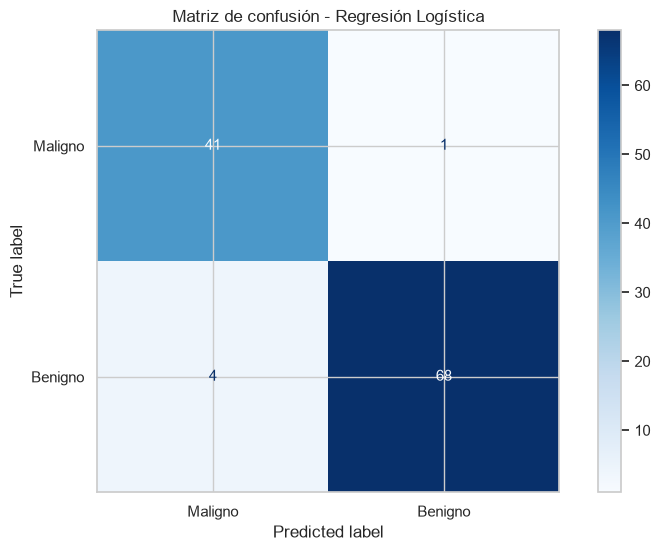

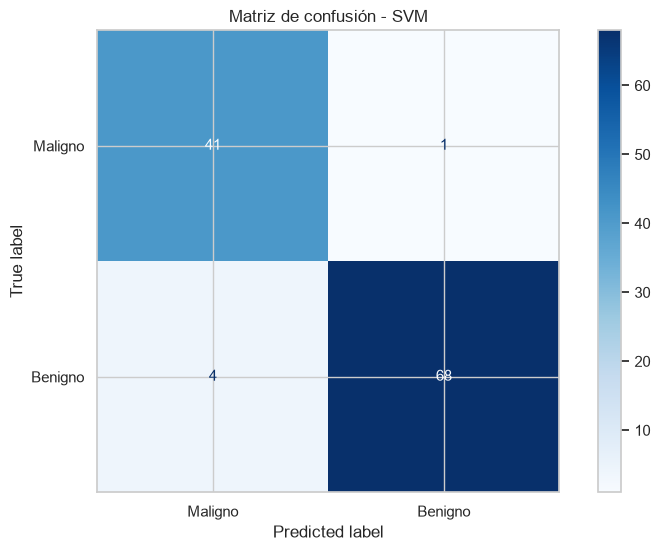

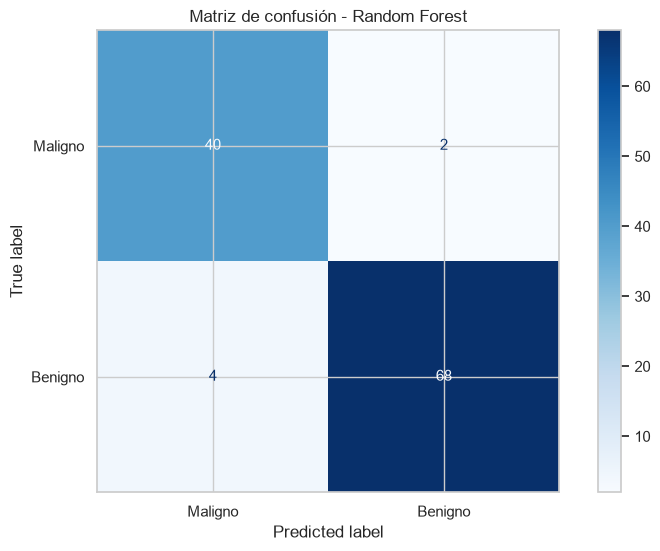

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for nombre, modelo in modelos_optimizados.items():

    y_pred = modelo.predict(X_test)

    matriz = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Maligno", "Benigno"]
    )

    visualizacion.plot(cmap="Blues")
    plt.title(f"Matriz de confusión - {nombre}")
    plt.show()

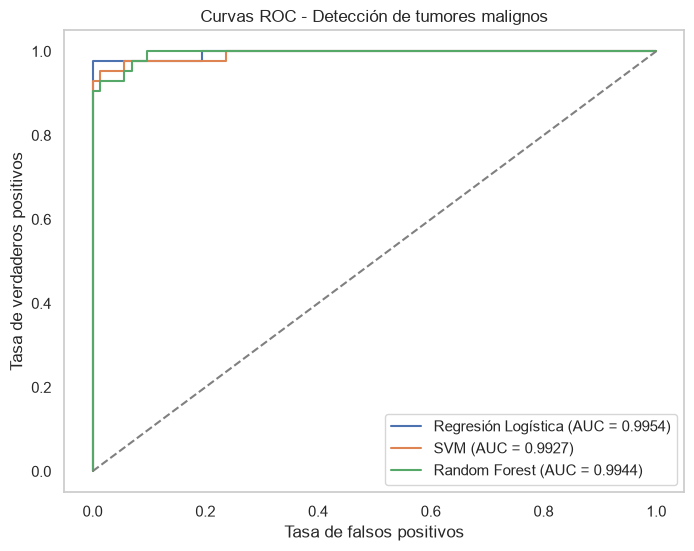

In [59]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Convertir la clase maligna (0) en la clase positiva
y_test_maligno = (y_test == 0).astype(int)

plt.figure(figsize=(8, 6))

for nombre, modelo in modelos_optimizados.items():

    # Obtener la probabilidad de la clase maligna
    indice_maligno = list(modelo.classes_).index(0)
    prob_maligno = modelo.predict_proba(X_test)[:, indice_maligno]

    fpr, tpr, _ = roc_curve(
        y_test_maligno,
        prob_maligno
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{nombre} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC - Detección de tumores malignos")

plt.legend(loc="lower right")
plt.grid()
plt.show()

In [60]:
import numpy as np

print("Distribución de clases en y_test:")
valores, cantidades = np.unique(y_test, return_counts=True)

for valor, cantidad in zip(valores, cantidades):
    print(f"Clase {valor}: {cantidad} muestras")

Distribución de clases en y_test:
Clase 0: 42 muestras
Clase 1: 72 muestras


In [61]:
print("MODELOS Y ESTIMADORES DISPONIBLES:\n")

for nombre, objeto in globals().copy().items():
    if hasattr(objeto, "predict") and hasattr(objeto, "fit"):
        print(f"{nombre}: {type(objeto).__name__}")

MODELOS Y ESTIMADORES DISPONIBLES:

LogisticRegression: type
KNeighborsClassifier: ABCMeta
SVC: ABCMeta
DecisionTreeClassifier: ABCMeta
RandomForestClassifier: ABCMeta
GaussianNB: ABCMeta
MLPClassifier: ABCMeta
Pipeline: ABCMeta
modelo: RandomForestClassifier
modelo_fold: Pipeline
GridSearchCV: ABCMeta
pipeline_logistica: Pipeline
grid_logistica: GridSearchCV
CalibratedClassifierCV: type
pipeline_svm_interno: Pipeline
modelo_svm_calibrado: CalibratedClassifierCV
grid_svm: GridSearchCV
modelo_rf: RandomForestClassifier
grid_rf: GridSearchCV


In [62]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Modelo Naive Bayes
pipeline_nb = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", GaussianNB())
])

# Modelo de red neuronal MLP
pipeline_mlp = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=2000,
        early_stopping=True,
        random_state=42
    ))
])

# Entrenamiento con los datos de entrenamiento
pipeline_nb.fit(X_train, y_train)
pipeline_mlp.fit(X_train, y_train)

print("Modelos entrenados correctamente:")
print("Naive Bayes:", pipeline_nb)
print("Red neuronal MLP:", pipeline_mlp)

Modelos entrenados correctamente:
Naive Bayes: Pipeline(steps=[('escalado', StandardScaler()), ('modelo', GaussianNB())])
Red neuronal MLP: Pipeline(steps=[('escalado', StandardScaler()),
                ('modelo',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(64, 32), max_iter=2000,
                               random_state=42))])


In [63]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score
import numpy as np

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Priorizar la detección de tumores malignos (clase 0)
scoring_maligno = make_scorer(
    recall_score,
    pos_label=0
)

# Espacio de búsqueda para Naive Bayes
parametros_nb = {
    "modelo__var_smoothing": np.logspace(-12, -6, 7)
}

# Espacio de búsqueda para MLP
parametros_mlp = {
    "modelo__hidden_layer_sizes": [
        (32,),
        (64, 32)
    ],
    "modelo__alpha": [
        0.0001,
        0.001,
        0.01
    ]
}

# Optimización de Naive Bayes
grid_nb = GridSearchCV(
    pipeline_nb,
    parametros_nb,
    cv=cv,
    scoring=scoring_maligno,
    n_jobs=-1
)

grid_nb.fit(X_train, y_train)

# Optimización de MLP
grid_mlp = GridSearchCV(
    pipeline_mlp,
    parametros_mlp,
    cv=cv,
    scoring=scoring_maligno,
    n_jobs=-1
)

grid_mlp.fit(X_train, y_train)

print("OPTIMIZACIÓN TERMINADA\n")

print("Naive Bayes")
print("Mejor recall:", grid_nb.best_score_)
print("Mejores parámetros:", grid_nb.best_params_)

print("\nRed neuronal MLP")
print("Mejor recall:", grid_mlp.best_score_)
print("Mejores parámetros:", grid_mlp.best_params_)

OPTIMIZACIÓN TERMINADA

Naive Bayes
Mejor recall: 0.9
Mejores parámetros: {'modelo__var_smoothing': np.float64(1e-12)}

Red neuronal MLP
Mejor recall: 0.9117647058823529
Mejores parámetros: {'modelo__alpha': 0.0001, 'modelo__hidden_layer_sizes': (64, 32)}


In [64]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Modelos optimizados y modelo de referencia
modelos_finales = {
    "Regresión Logística": grid_logistica.best_estimator_,
    "Naive Bayes": grid_nb.best_estimator_,
    "SVM": grid_svm.best_estimator_,
    "MLP": grid_mlp.best_estimator_,
    "Random Forest (adicional)": grid_rf.best_estimator_
}

resultados_finales = []

# Convertir la clase maligna (0) en clase positiva
y_test_maligno = (y_test == 0).astype(int)

for nombre, modelo in modelos_finales.items():

    y_pred = modelo.predict(X_test)

    # Obtener probabilidades de la clase maligna
    y_prob = modelo.predict_proba(X_test)
    indice_maligno = list(modelo.classes_).index(0)
    prob_maligno = y_prob[:, indice_maligno]

    resultados_finales.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test_maligno, prob_maligno
        )
    })

tabla_resultados = pd.DataFrame(resultados_finales)

tabla_resultados.round(4)

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Regresión Logística,0.9561,0.9111,0.9762,0.9425,0.9954
1,Naive Bayes,0.9298,0.9048,0.9048,0.9048,0.9868
2,SVM,0.9561,0.9111,0.9762,0.9425,0.9927
3,MLP,0.9474,0.9500,0.9048,0.9268,0.9927
4,Random Forest (adicional),0.9474,0.9091,0.9524,0.9302,0.9944


In [65]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

# Evaluar el recall de la clase maligna (0)
scoring_maligno = make_scorer(
    recall_score,
    pos_label=0
)

resultados_variabilidad = []

for nombre, modelo in modelos_finales.items():

    puntuaciones = cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_maligno,
        n_jobs=-1
    )

    resultados_variabilidad.append({
        "Modelo": nombre,
        "Recall promedio": puntuaciones.mean(),
        "Desviación estándar": puntuaciones.std(),
        "Recall mínimo": puntuaciones.min(),
        "Recall máximo": puntuaciones.max()
    })

tabla_variabilidad = pd.DataFrame(resultados_variabilidad)

print("VARIABILIDAD DEL RECALL EN VALIDACIÓN CRUZADA\n")
print(tabla_variabilidad.round(4).to_string(index=False))

VARIABILIDAD DEL RECALL EN VALIDACIÓN CRUZADA

                   Modelo  Recall promedio  Desviación estándar  Recall mínimo  Recall máximo
      Regresión Logística           0.9765               0.0118         0.9706         1.0000
              Naive Bayes           0.9000               0.0440         0.8529         0.9706
                      SVM           0.9647               0.0220         0.9412         1.0000
                      MLP           0.9118               0.0186         0.8824         0.9412
Random Forest (adicional)           0.9706               0.0263         0.9412         1.0000


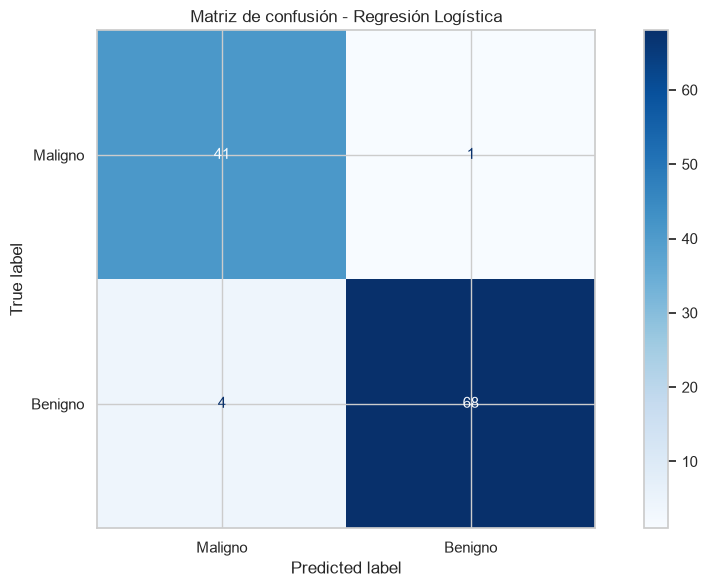

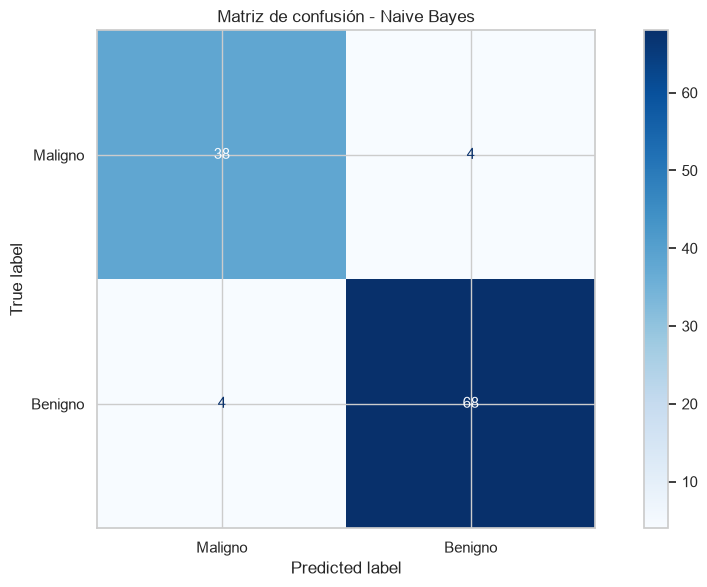

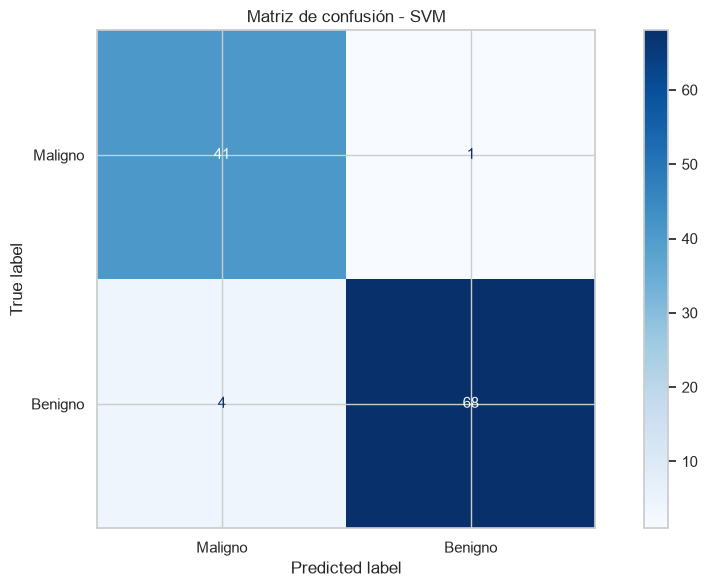

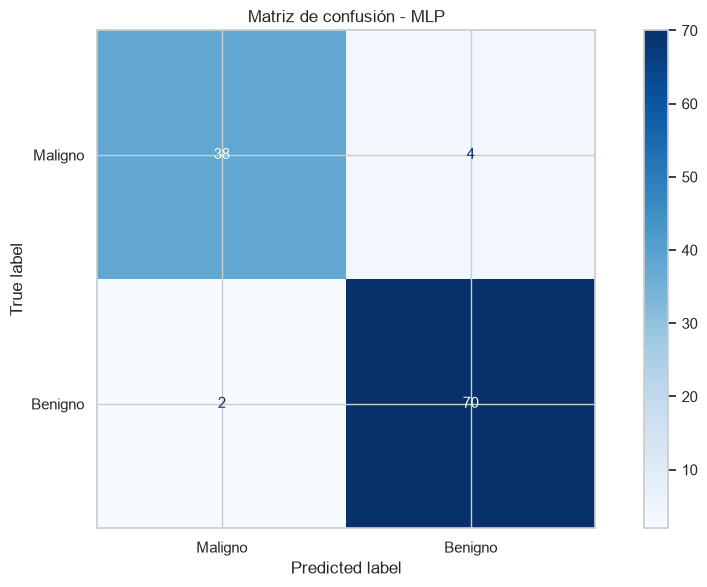

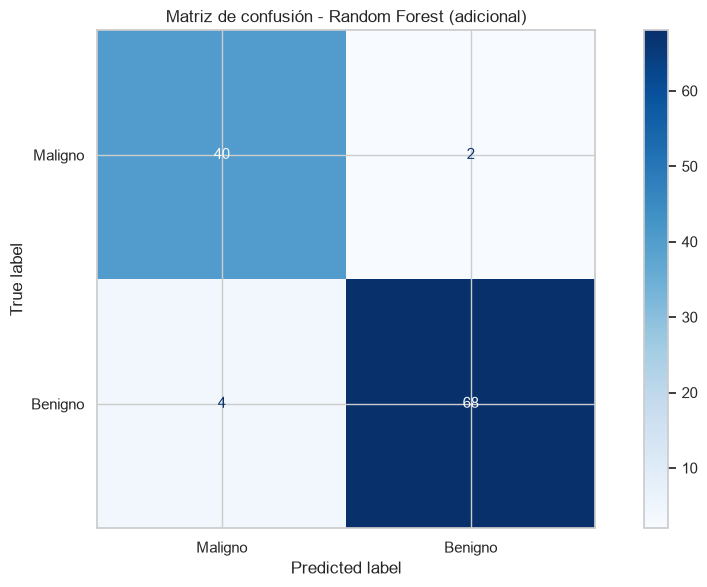

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for nombre, modelo in modelos_finales.items():

    y_pred = modelo.predict(X_test)

    matriz = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Maligno", "Benigno"]
    )

    visualizacion.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()

In [67]:
for nombre, modelo in modelos_finales.items():
    y_pred = modelo.predict(X_test)

    errores = X_test[y_test != y_pred].copy()
    errores["Diagnostico_real"] = y_test[y_test != y_pred]
    errores["Diagnostico_predicho"] = y_pred[y_test != y_pred]

    print(f"\n{nombre}")
    print(f"Número de errores: {len(errores)}")
    display(errores[["Diagnostico_real", "Diagnostico_predicho"]])


Regresión Logística
Número de errores: 5


,Diagnostico_real,Diagnostico_predicho
363,1,0
541,1,0
542,1,0
73,0,1
291,1,0



Naive Bayes
Número de errores: 8


,Diagnostico_real,Diagnostico_predicho
541,1,0
247,1,0
41,0,1
73,0,1
385,0,1
205,0,1
504,1,0
128,1,0



SVM
Número de errores: 5


,Diagnostico_real,Diagnostico_predicho
363,1,0
541,1,0
526,1,0
73,0,1
291,1,0



MLP
Número de errores: 6


,Diagnostico_real,Diagnostico_predicho
541,1,0
261,0,1
73,0,1
385,0,1
205,0,1
128,1,0



Random Forest (adicional)
Número de errores: 6


,Diagnostico_real,Diagnostico_predicho
363,1,0
541,1,0
406,1,0
41,0,1
73,0,1
128,1,0



Regresión Logística
[[41  1]
 [ 4 68]]


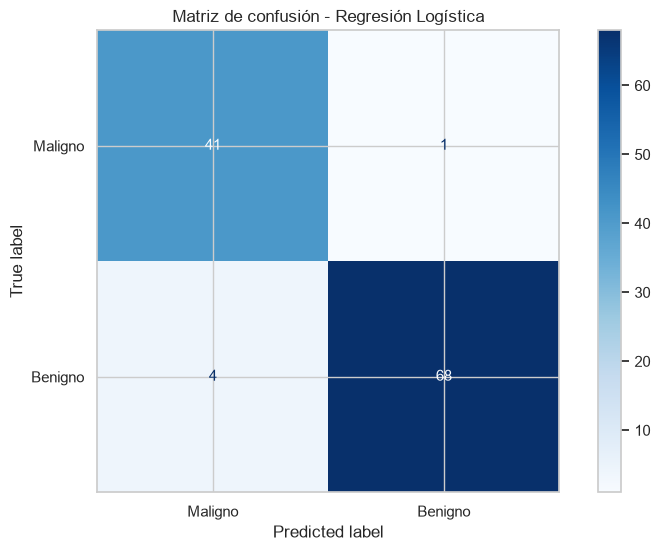


Naive Bayes
[[38  4]
 [ 4 68]]


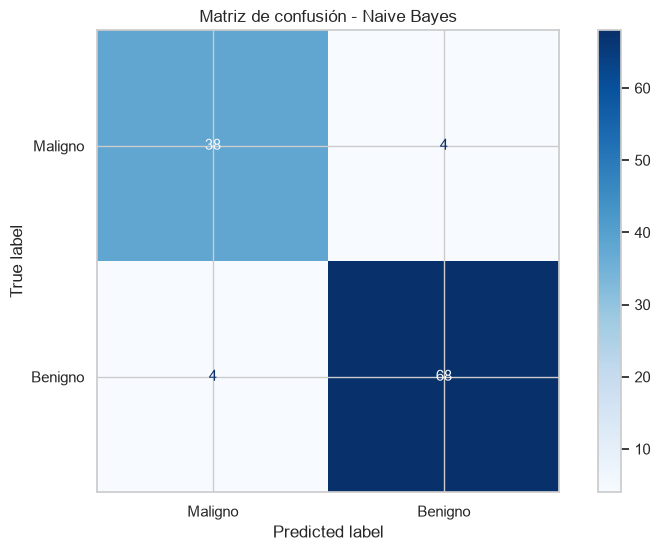


SVM
[[41  1]
 [ 4 68]]


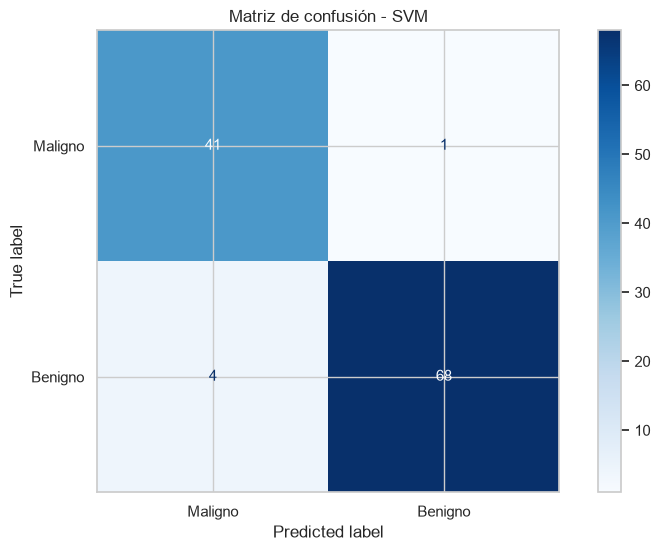


MLP
[[38  4]
 [ 2 70]]


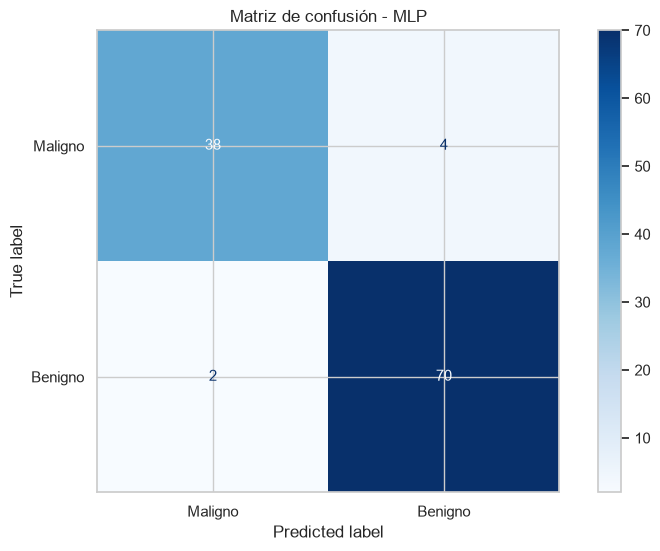


Random Forest (adicional)
[[40  2]
 [ 4 68]]


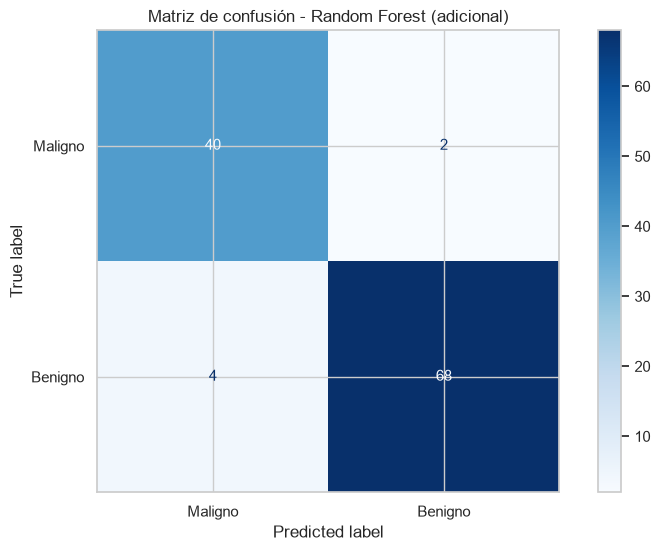

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for nombre, modelo in modelos_finales.items():
    y_pred = modelo.predict(X_test)

    matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f"\n{nombre}")
    print(matriz)

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Maligno", "Benigno"]
    )

    visualizacion.plot(cmap="Blues")
    plt.title(f"Matriz de confusión - {nombre}")
    plt.show()

# 11.4 Conclusión del análisis de errores
El análisis de las matrices de confusión muestra que la Regresión Logística y SVM obtuvieron el mejor desempeño en la identificación de tumores malignos, con 41 de 42 casos detectados correctamente. Random Forest también presentó un buen resultado, con 40 casos identificados. Por otro lado, Naive Bayes y MLP presentaron cuatro falsos negativos cada uno. Debido a que en un problema de diagnóstico de cáncer es especialmente importante reducir los falsos negativos, la Regresión Logística y SVM destacan como los modelos más adecuados según los resultados obtenidos.

# 12. Conclusiones generales
El desarrollo de este proyecto permitió aplicar técnicas de ciencia de datos y aprendizaje automático para la clasificación de tumores mamarios utilizando el conjunto de datos Breast Cancer Wisconsin Diagnostic.

Durante el análisis exploratorio se identificaron las características principales del conjunto de datos, la distribución de las clases y las relaciones entre las variables. Posteriormente, se realizó el preprocesamiento de los datos, incluyendo la estandarización de las características y la división en conjuntos de entrenamiento y prueba.

Se entrenaron y evaluaron cinco modelos: Regresión Logística, Naive Bayes, Support Vector Machine (SVM), Perceptrón Multicapa (MLP) y Random Forest. Los resultados mostraron que la Regresión Logística y SVM obtuvieron el mejor desempeño general, alcanzando una exactitud de 95.61% y un recall de 97.62% para la clase de tumores malignos.

La Regresión Logística destacó por su capacidad para identificar correctamente 41 de los 42 casos malignos del conjunto de prueba, presentando únicamente un falso negativo. SVM obtuvo el mismo resultado en la clasificación, aunque la Regresión Logística presentó un valor ligeramente superior de ROC-AUC.

Por otra parte, Naive Bayes y MLP presentaron mayores dificultades para identificar algunos casos malignos, mientras que Random Forest mostró un desempeño intermedio.

En conclusión, la Regresión Logística se considera el modelo más conveniente entre los evaluados, debido a su equilibrio entre las métricas de clasificación, su alto recall y su capacidad para reducir los falsos negativos. Sin embargo, estos resultados corresponden a un conjunto de datos específico y no sustituyen la valoración de profesionales médicos. En trabajos futuros se podrían explorar técnicas adicionales de selección de características, optimización de umbrales y validación con conjuntos de datos independientes.

# 13. Reproducibilidad del proyecto

In [69]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib

print("Versiones de las librerías utilizadas:")
print("Python:", __import__("sys").version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Versiones de las librerías utilizadas:
Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
NumPy: 2.4.6
Pandas: 3.0.3
Scikit-learn: 1.9.0
Matplotlib: 3.11.0


In [70]:
contenido_requirements = """
numpy==2.4.6
pandas==3.0.3
scikit-learn==1.9.0
matplotlib==3.11.0
"""

with open("requirements.txt", "w", encoding="utf-8") as archivo:
    archivo.write(contenido_requirements.strip())

print("Archivo requirements.txt creado correctamente.")

Archivo requirements.txt creado correctamente.


In [71]:
contenido_readme = """
# Clasificación de tumores mamarios mediante aprendizaje automático

## Descripción del proyecto

Este proyecto utiliza técnicas de ciencia de datos y aprendizaje automático
para clasificar tumores mamarios como malignos o benignos mediante el
conjunto de datos Breast Cancer Wisconsin Diagnostic.

## Objetivo

Evaluar y comparar diferentes modelos de clasificación para identificar
tumores malignos, dando especial importancia al recall de esta clase,
debido a la relevancia de reducir los falsos negativos.

## Dataset

Breast Cancer Wisconsin Diagnostic.

- 569 observaciones.
- 30 características numéricas.
- 212 casos malignos.
- 357 casos benignos.

Codificación de las clases:
- 0: Maligno.
- 1: Benigno.

## Modelos evaluados

- Regresión Logística.
- Naive Bayes.
- Support Vector Machine (SVM).
- Perceptrón Multicapa (MLP).
- Random Forest (modelo adicional).

## Resultados principales

El modelo de Regresión Logística obtuvo los mejores resultados generales:

- Accuracy: 95.61%
- Precision: 91.11%
- Recall: 97.62%
- F1-score: 94.25%
- ROC-AUC: 99.54%

## Tecnologías utilizadas

- Python 3.14.6
- NumPy 2.4.6
- Pandas 3.0.3
- Scikit-learn 1.9.0
- Matplotlib 3.11.0

## Ejecución

1. Instalar las dependencias:

   pip install -r requirements.txt

2. Abrir el notebook 01_analisis_exploratorio.ipynb.
3. Ejecutar las celdas en orden.

## Reproducibilidad

Se utilizó random_state=42 para mantener la reproducibilidad
de las particiones y los experimentos correspondientes.

## Consideraciones

Este proyecto tiene fines académicos y experimentales.
Los resultados no sustituyen un diagnóstico médico profesional.
"""

with open("README.md", "w", encoding="utf-8") as archivo:
    archivo.write(contenido_readme.strip())

print("Archivo README.md creado correctamente.")

Archivo README.md creado correctamente.


In [72]:
import os

print("Carpeta actual del proyecto:")
print(os.getcwd())

print("\nArchivos encontrados:")
for archivo in os.listdir():
    print(archivo)

Carpeta actual del proyecto:
C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\notebooks

Archivos encontrados:
.ipynb_checkpoints
01_analisis_exploratorio.ipynb
README.md
requirements.txt


In [73]:
import os
import shutil

carpeta_proyecto = os.path.dirname(os.getcwd())

shutil.move(
    "README.md",
    os.path.join(carpeta_proyecto, "README.md")
)

shutil.move(
    "requirements.txt",
    os.path.join(carpeta_proyecto, "requirements.txt")
)

# Actualizar la ruta del notebook en el README
ruta_readme = os.path.join(carpeta_proyecto, "README.md")

with open(ruta_readme, "r", encoding="utf-8") as archivo:
    contenido = archivo.read()

contenido = contenido.replace(
    "Abrir el notebook 01_analisis_exploratorio.ipynb.",
    "Abrir notebooks/01_analisis_exploratorio.ipynb."
)

with open(ruta_readme, "w", encoding="utf-8") as archivo:
    archivo.write(contenido)

print("Archivos organizados correctamente.")
print("\nCarpeta principal:", carpeta_proyecto)
print("\nContenido:")
for elemento in os.listdir(carpeta_proyecto):
    print(elemento)

Archivos organizados correctamente.

Carpeta principal: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos

Contenido:
data
notebooks
README.md
report
requirements.txt
results


In [74]:
import os

carpeta_proyecto = os.path.dirname(os.getcwd())

for carpeta in ["data", "report", "results"]:
    ruta = os.path.join(carpeta_proyecto, carpeta)

    print(f"\nContenido de {carpeta}/")

    archivos = os.listdir(ruta)

    if archivos:
        for archivo in archivos:
            print(" -", archivo)
    else:
        print(" (Carpeta vacía)")


Contenido de data/
 - processed
 - raw

Contenido de report/
 - articulo_cientifico.md

Contenido de results/
 - comparacion_antes_despues.csv
 - comparacion_modelos_cv.csv
 - figures
 - resultados_optimizacion.csv
 - tables


In [75]:
import os
import pandas as pd

carpeta_proyecto = os.path.dirname(os.getcwd())
carpeta_resultados = os.path.join(carpeta_proyecto, "results")

for carpeta, subcarpetas, archivos in os.walk(carpeta_resultados):
    print(f"\n📁 {os.path.relpath(carpeta, carpeta_proyecto)}")

    for archivo in archivos:
        ruta = os.path.join(carpeta, archivo)
        print("   ", archivo)

        if archivo.endswith(".csv"):
            datos = pd.read_csv(ruta)
            print("Columnas:", list(datos.columns))
            display(datos.head())


📁 results
    comparacion_antes_despues.csv
Columnas: ['Modelo', 'Recall_Original', 'Recall_Optimizado', 'Diferencia']


,Modelo,Recall_Original,Recall_Optimizado,Diferencia
0,Regresion_Logistica,0.964706,0.976471,0.011765
1,SVM,0.952941,0.964706,0.011765
2,Random_Forest,0.958824,0.970588,0.011765


    comparacion_modelos_cv.csv
Columnas: ['Modelo', 'Accuracy_Media', 'Accuracy_STD', 'Precision_Maligno_Media', 'Recall_Maligno_Media', 'F1_Maligno_Media', 'Especificidad_Media', 'ROC_AUC_Media', 'ROC_AUC_STD']


,Modelo,Accuracy_Media,Accuracy_STD,Precision_Maligno_Media,Recall_Maligno_Media,F1_Maligno_Media,Especificidad_Media,ROC_AUC_Media,ROC_AUC_STD
0,Regresion_Logistica,0.978022,0.010989,0.976975,0.964706,0.970308,0.985965,0.995872,0.005545
1,Random_Forest,0.962637,0.019963,0.943968,0.958824,0.950604,0.964912,0.989577,0.009231
2,SVM,0.969231,0.016299,0.964948,0.952941,0.958265,0.978947,0.995562,0.005320
3,MLP,0.951648,0.026465,0.932941,0.941176,0.935889,0.957895,0.984004,0.010543
4,KNN,0.962637,0.012529,0.970725,0.929412,0.949042,0.982456,0.988235,0.009112


    resultados_optimizacion.csv
Columnas: ['Modelo', 'Recall_Optimizado', 'Mejores_Parametros']


,Modelo,Recall_Optimizado,Mejores_Parametros
0,Regresion_Logistica,0.976471,"{'modelo__C': 1, 'modelo__class_weight': 'bala..."
1,Random_Forest,0.970588,"{'class_weight': 'balanced', 'max_depth': None..."
2,SVM,0.964706,"{'estimator__modelo__C': 100, 'estimator__mode..."



📁 results\figures
    01_distribucion_clases.png
    02_histogramas_variables.png
    03_boxplots_variables.png
    04_matriz_correlacion.png
    05_comparacion_clases_violin.png
    06_correlaciones_diagnostico.png

📁 results\tables


In [76]:
import os

carpeta_proyecto = os.path.dirname(os.getcwd())
carpeta_tablas = os.path.join(carpeta_proyecto, "results", "tables")

print("Archivos de la carpeta tables:")

for archivo in os.listdir(carpeta_tablas):
    print("-", archivo)

Archivos de la carpeta tables:


In [77]:
import os

carpeta_proyecto = os.path.dirname(os.getcwd())
carpeta_figuras = os.path.join(carpeta_proyecto, "results", "figures")

for archivo in os.listdir(carpeta_figuras):
    ruta = os.path.join(carpeta_figuras, archivo)

    print(archivo, "-", os.path.getsize(ruta), "bytes")

01_distribucion_clases.png - 81565 bytes
02_histogramas_variables.png - 734742 bytes
03_boxplots_variables.png - 389342 bytes
04_matriz_correlacion.png - 482522 bytes
05_comparacion_clases_violin.png - 558292 bytes
06_correlaciones_diagnostico.png - 149347 bytes



 01_distribucion_clases.png


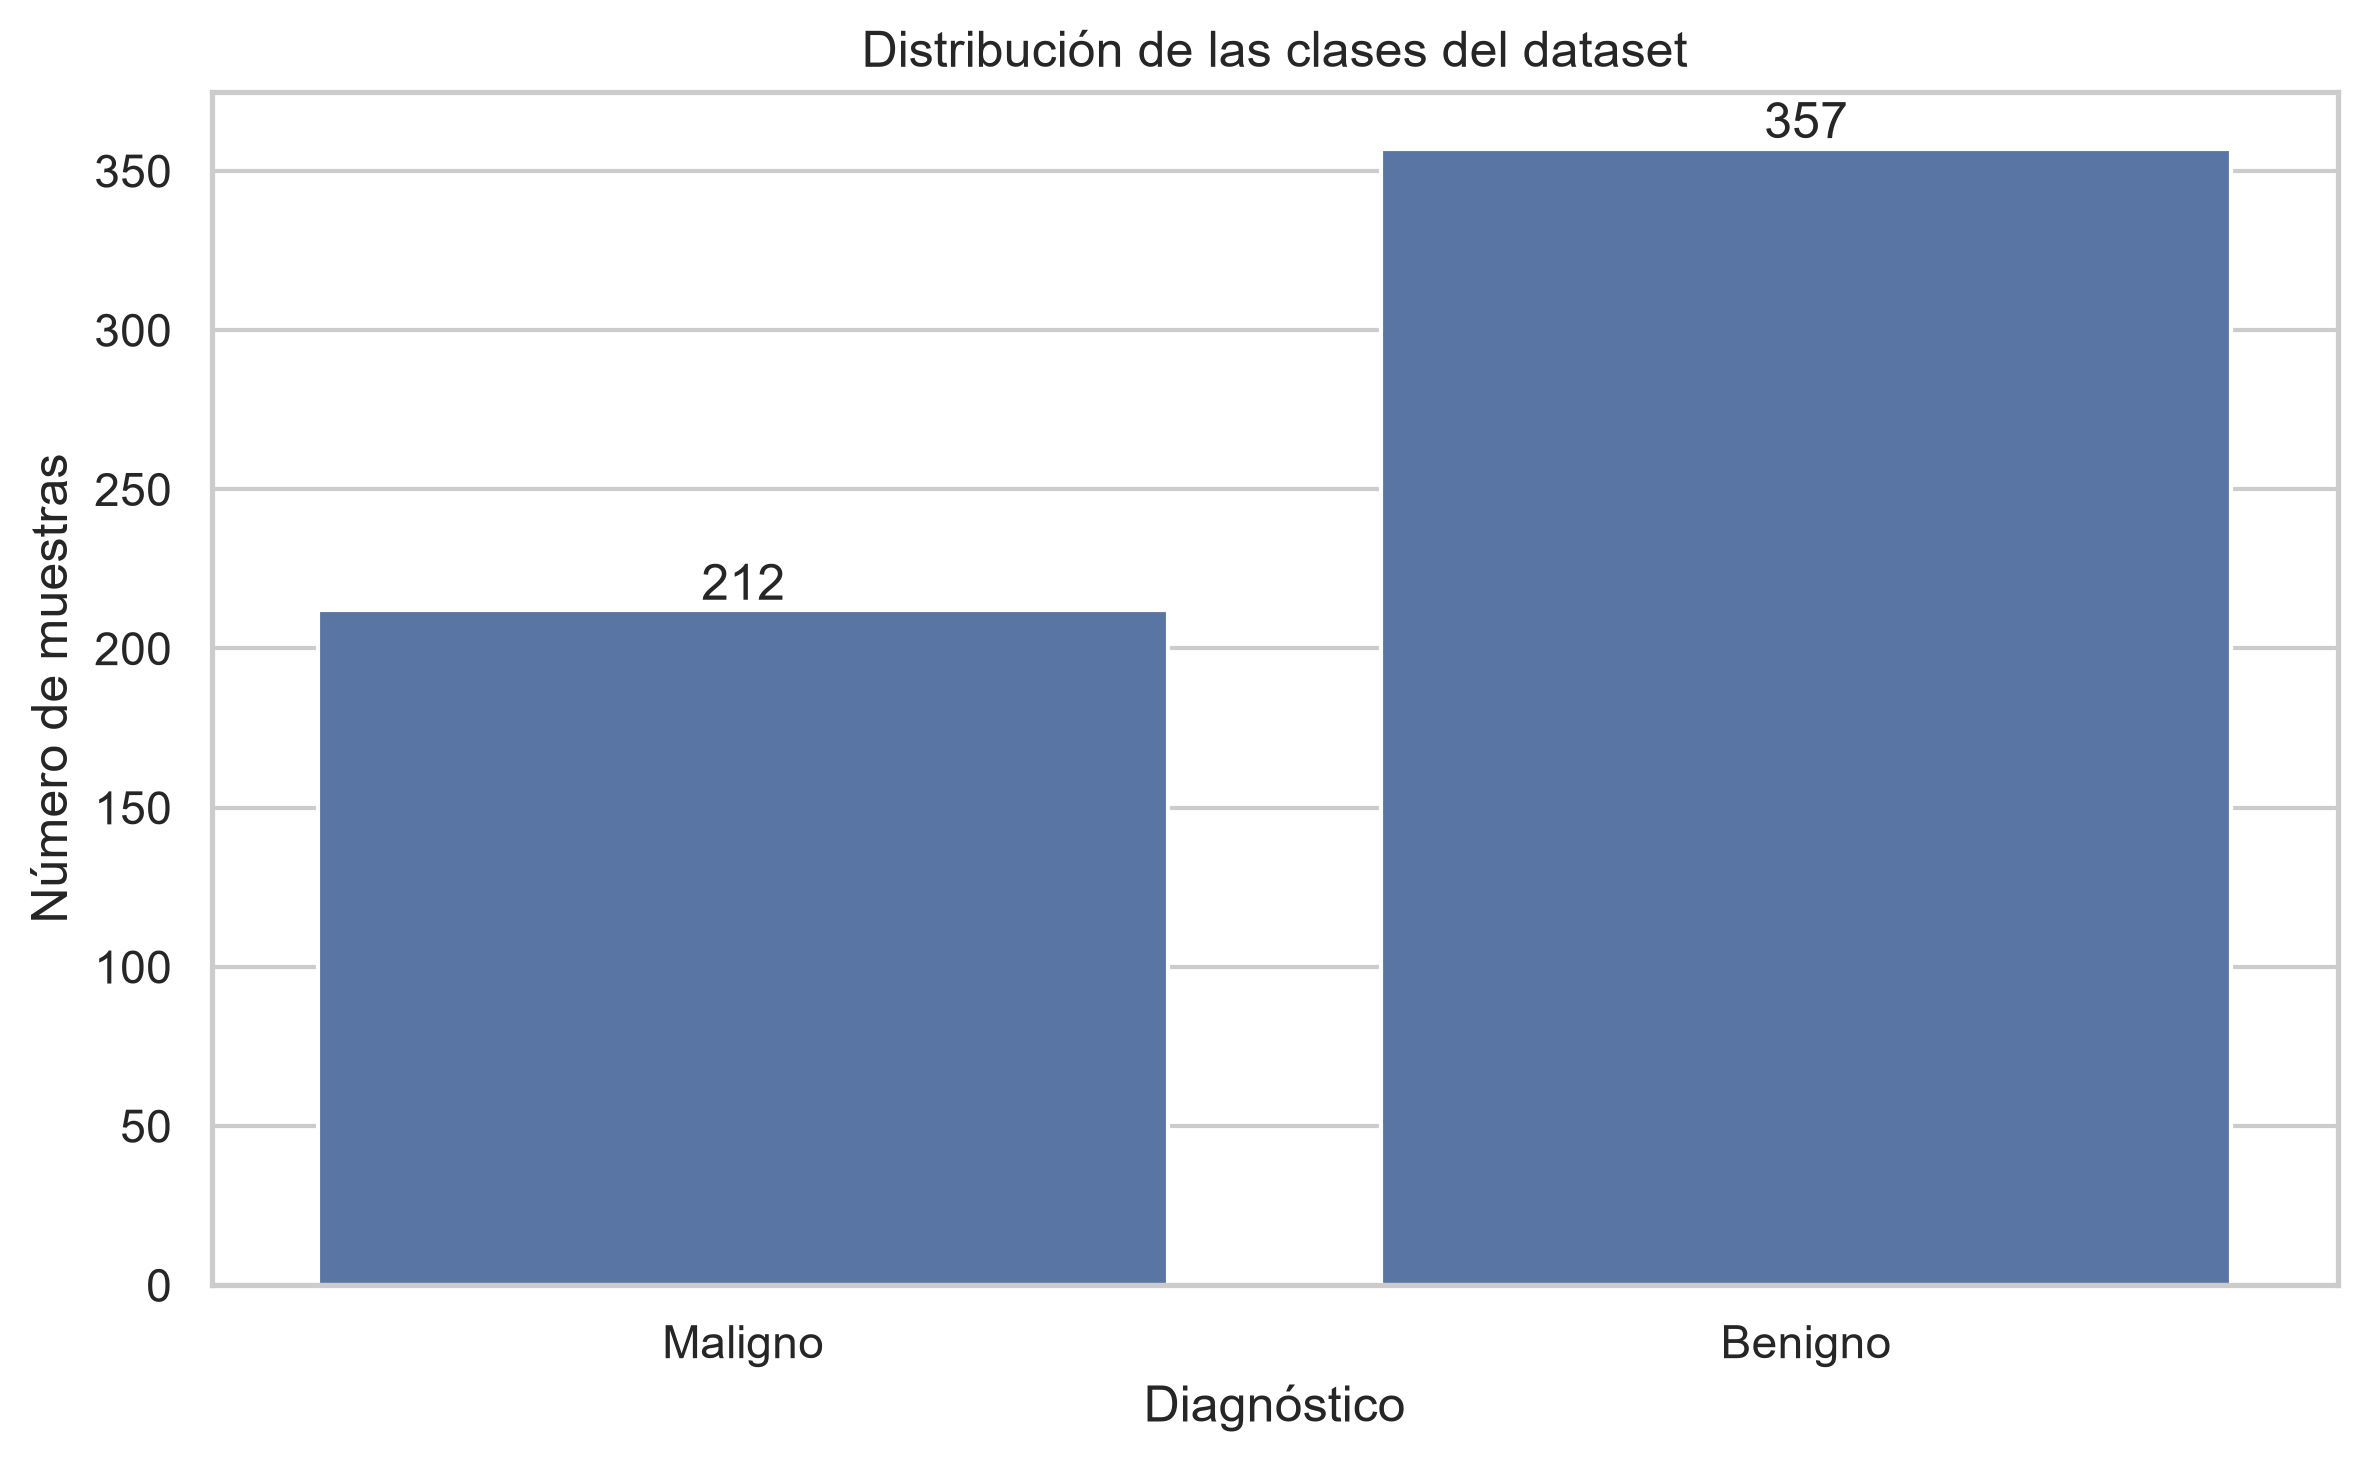


 02_histogramas_variables.png


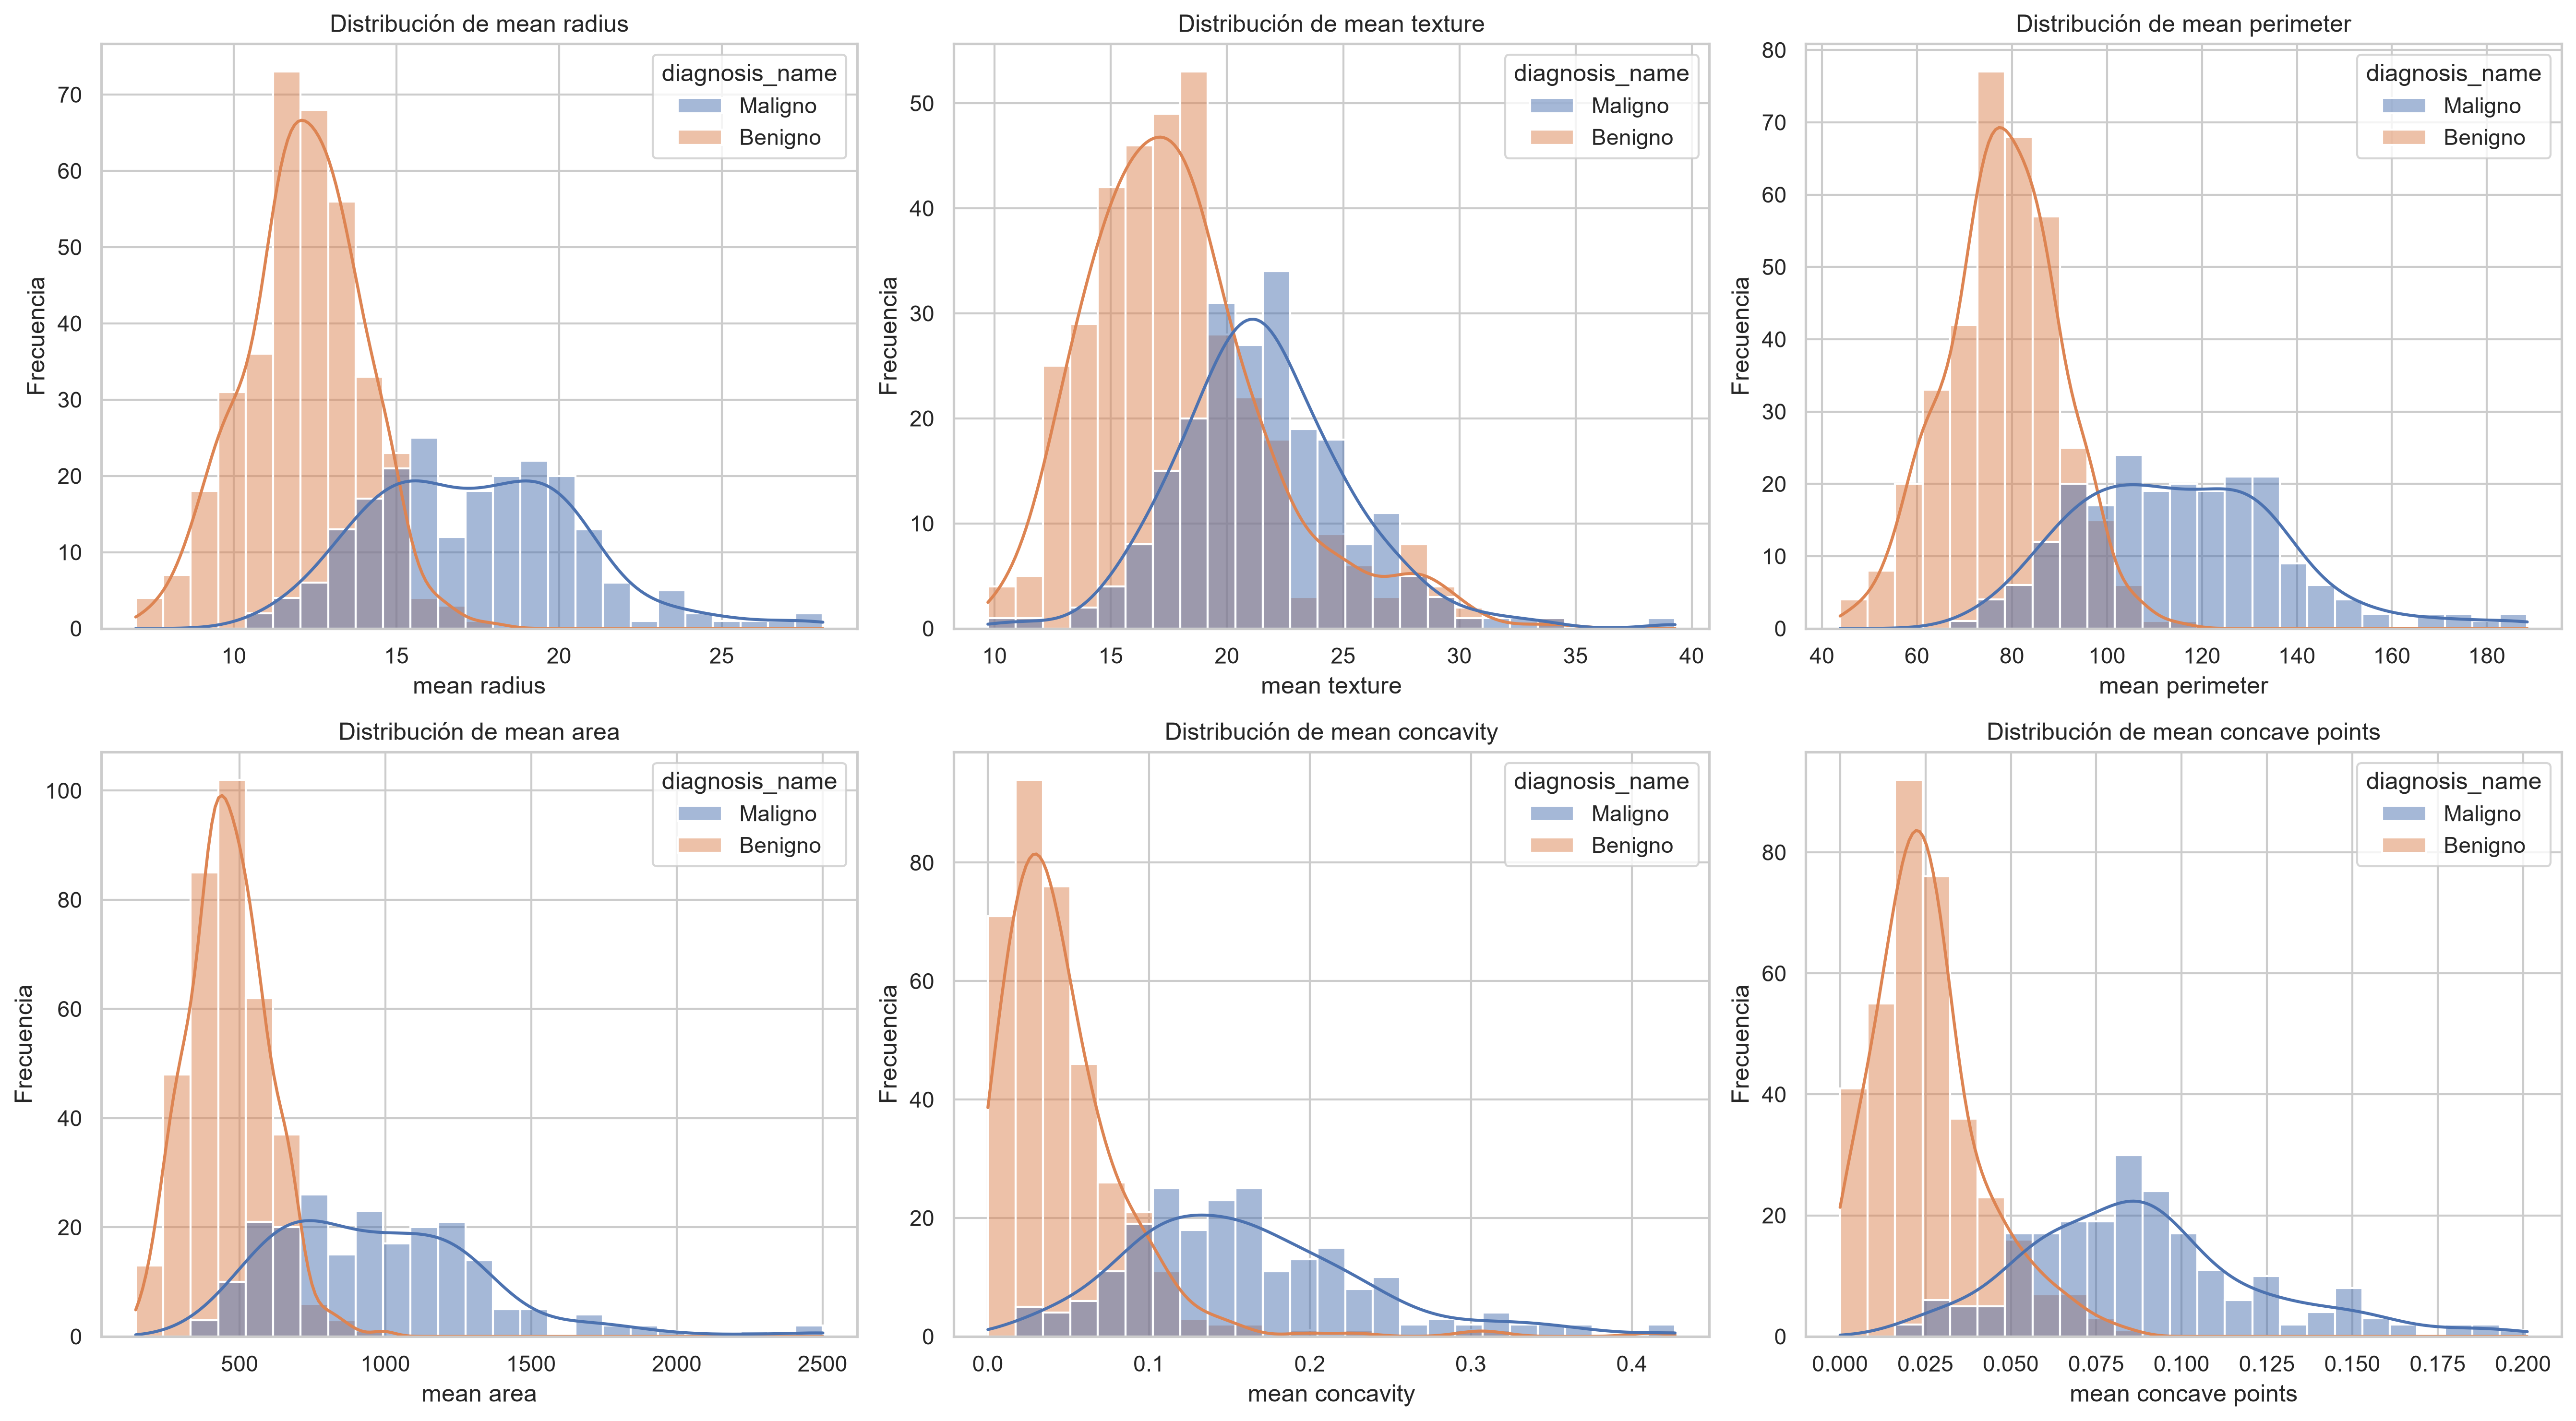


 03_boxplots_variables.png


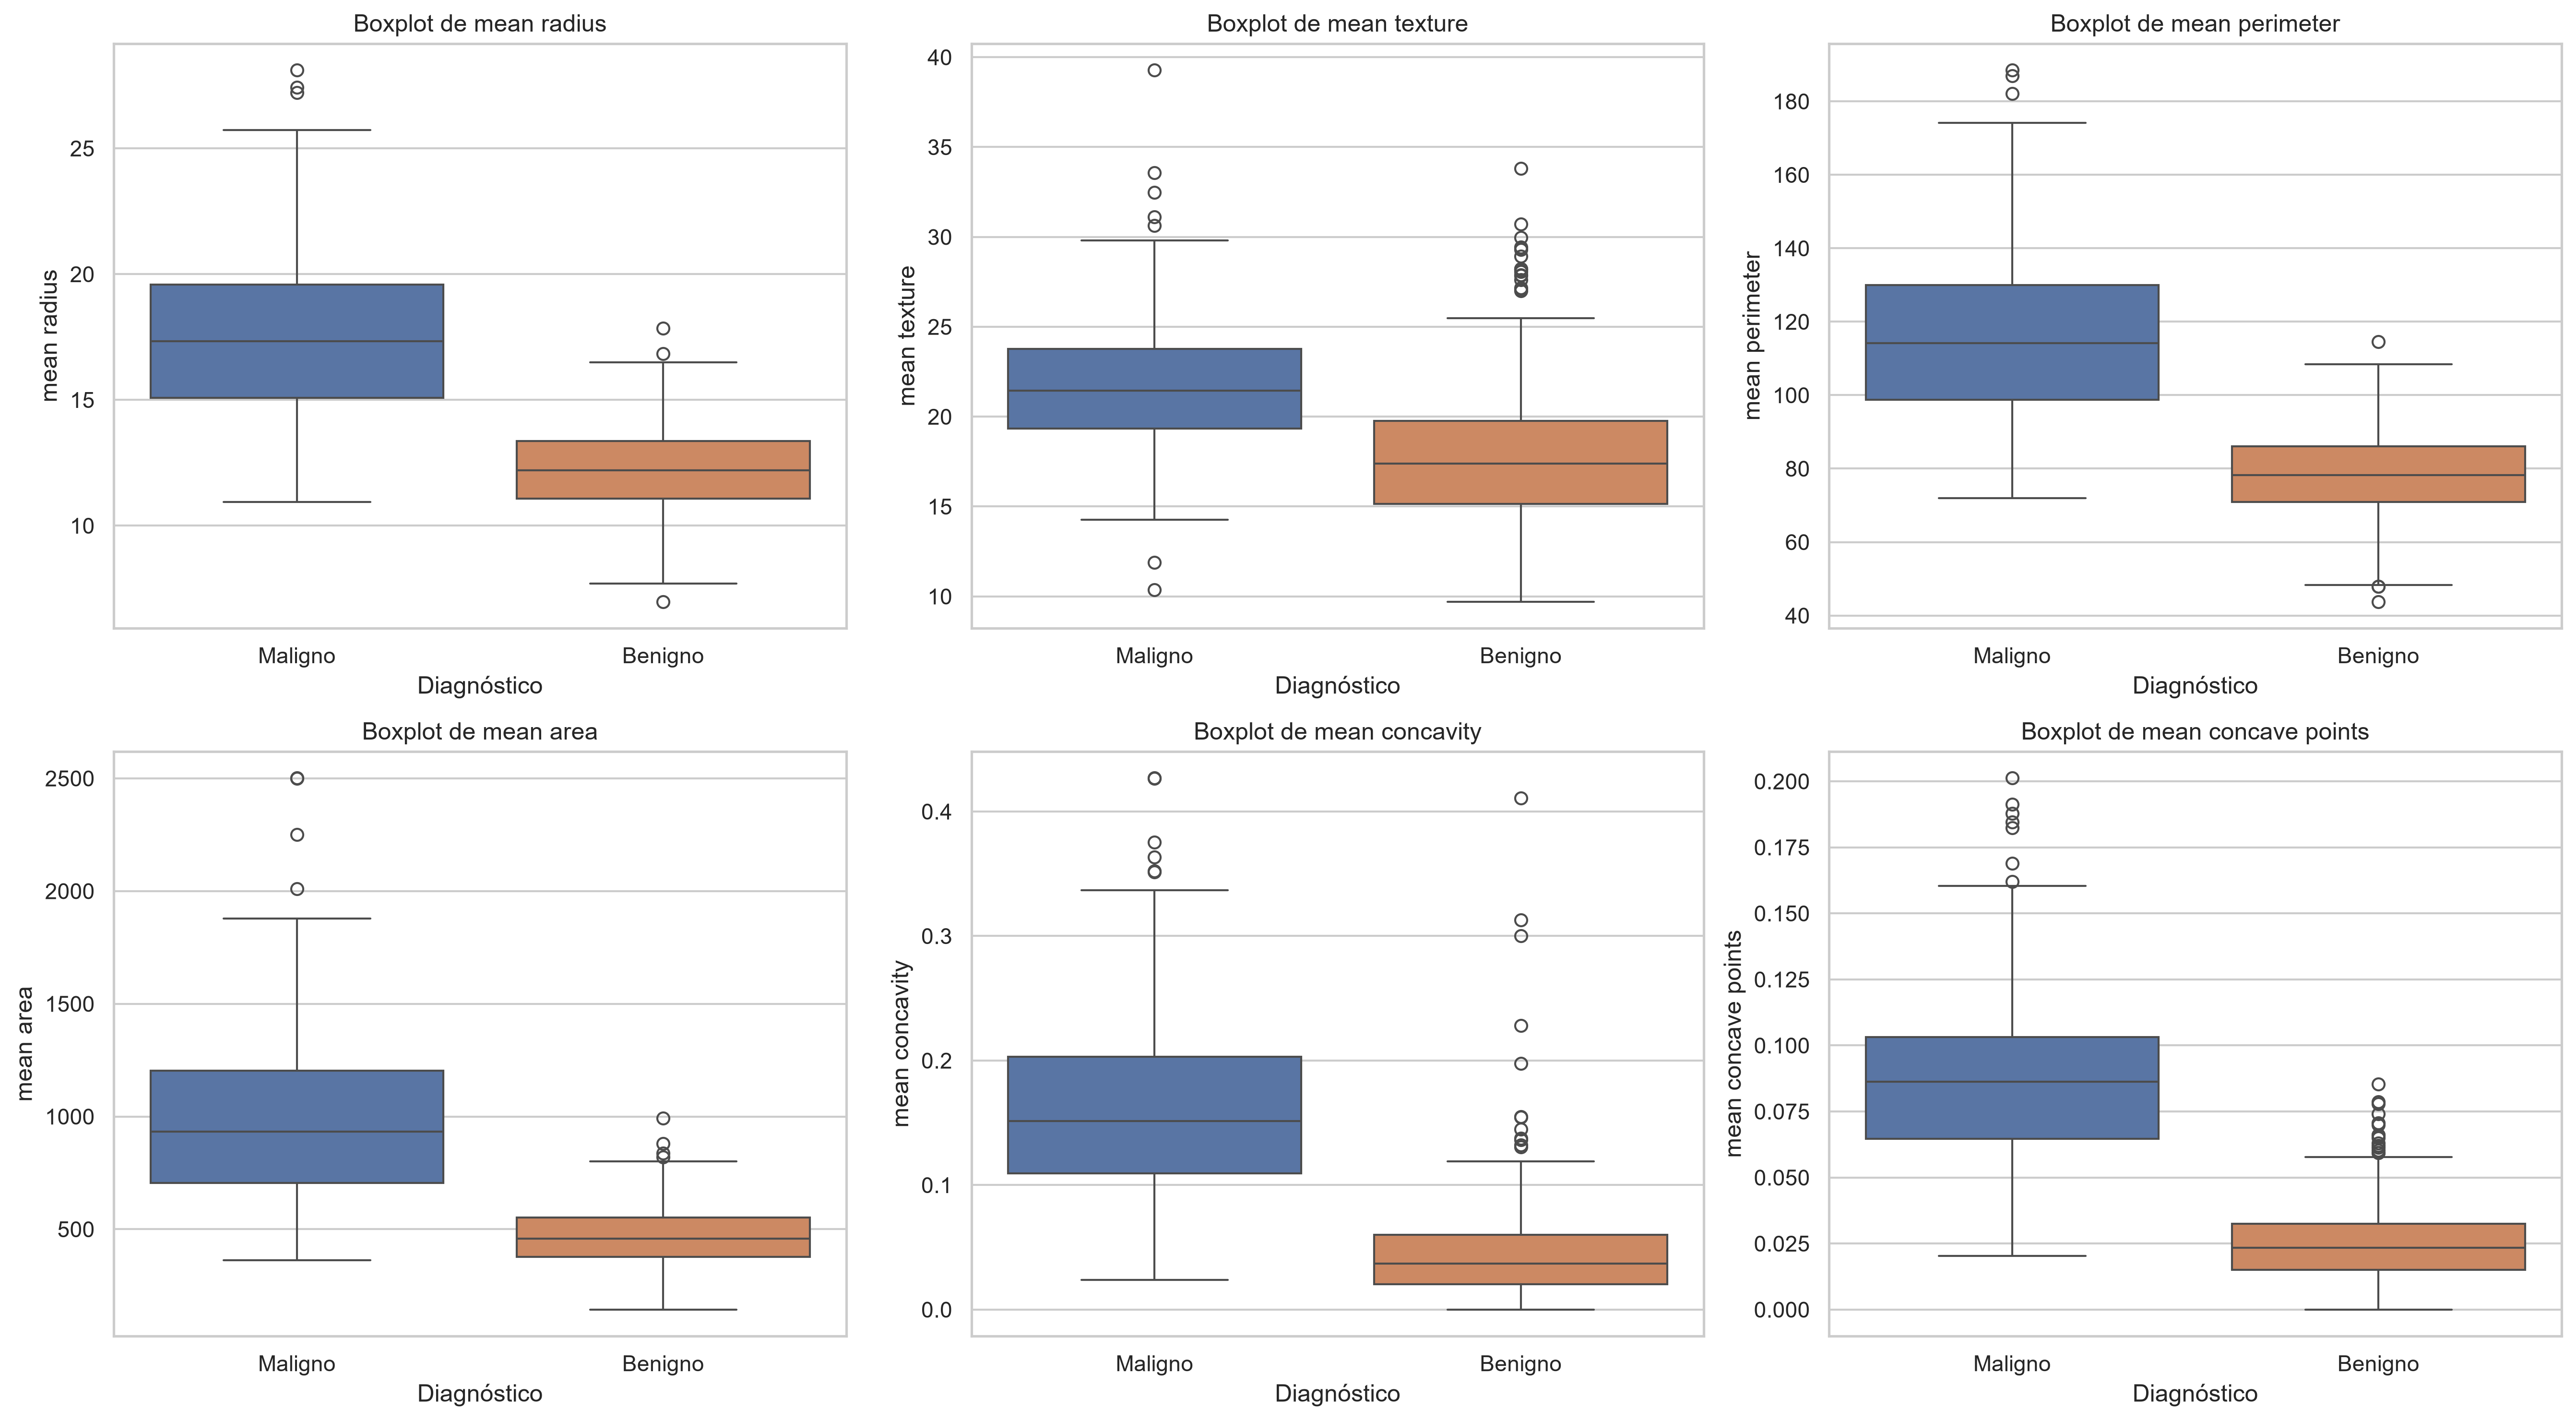


 04_matriz_correlacion.png


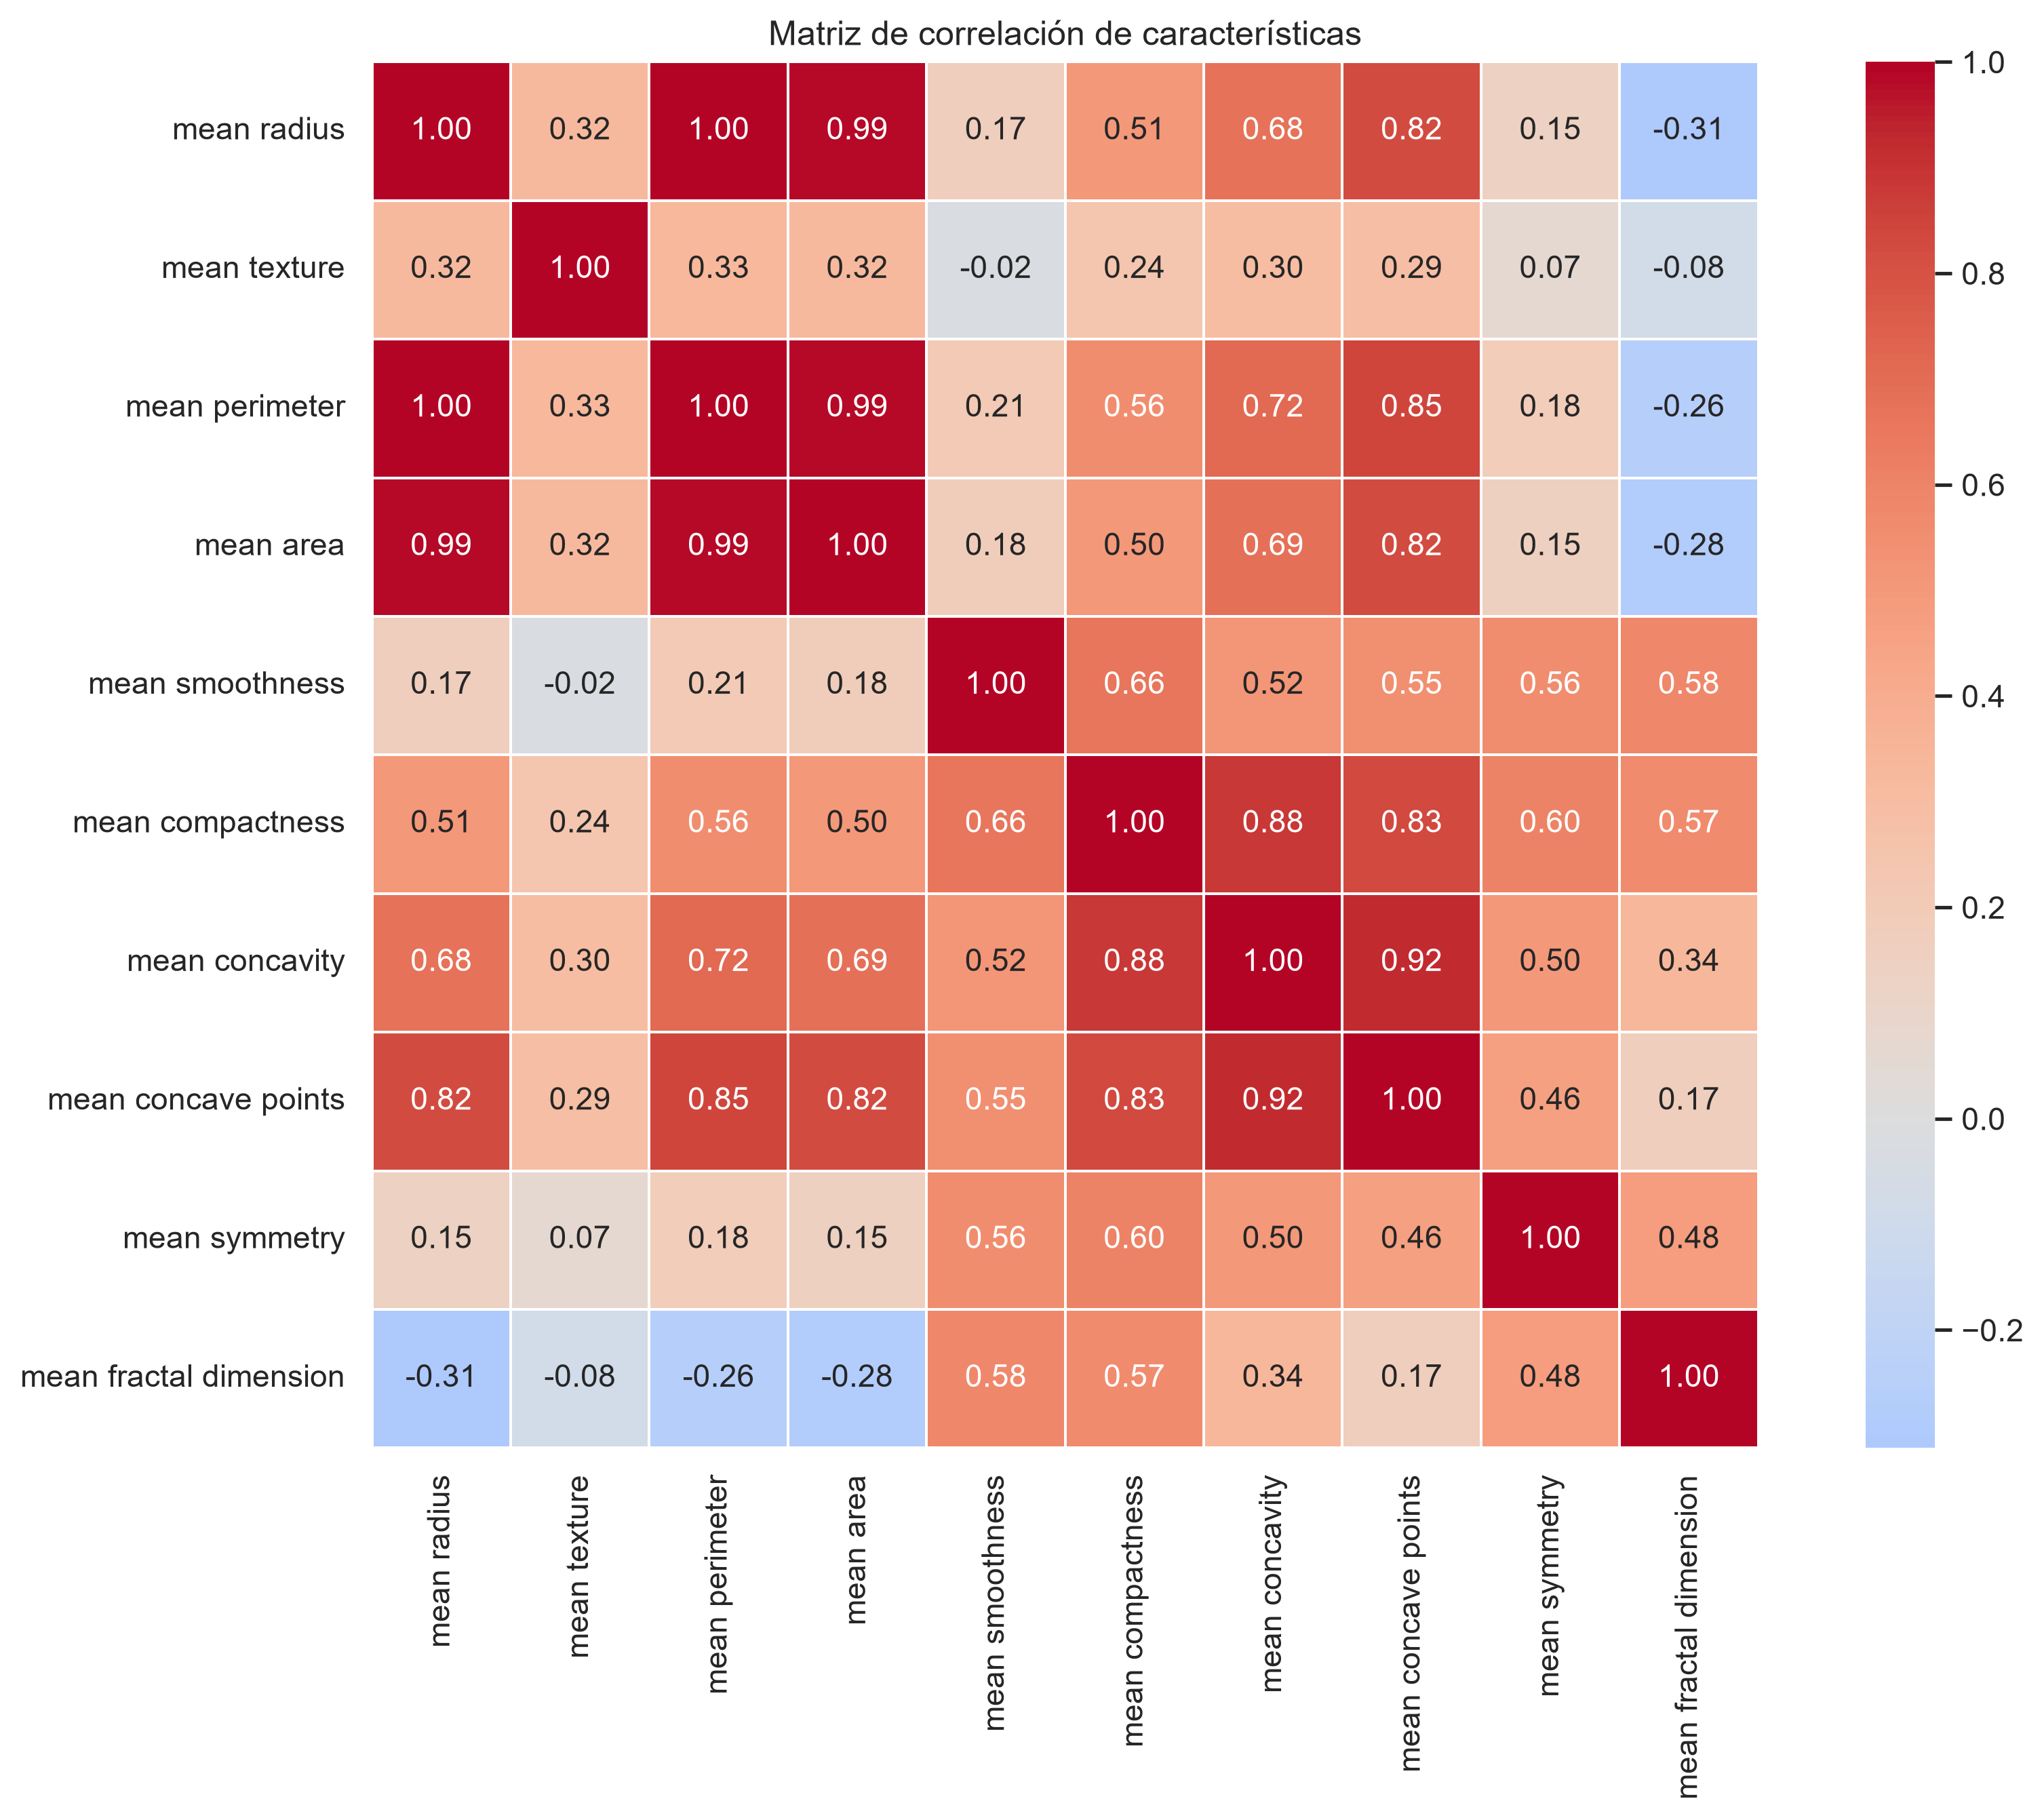


 05_comparacion_clases_violin.png


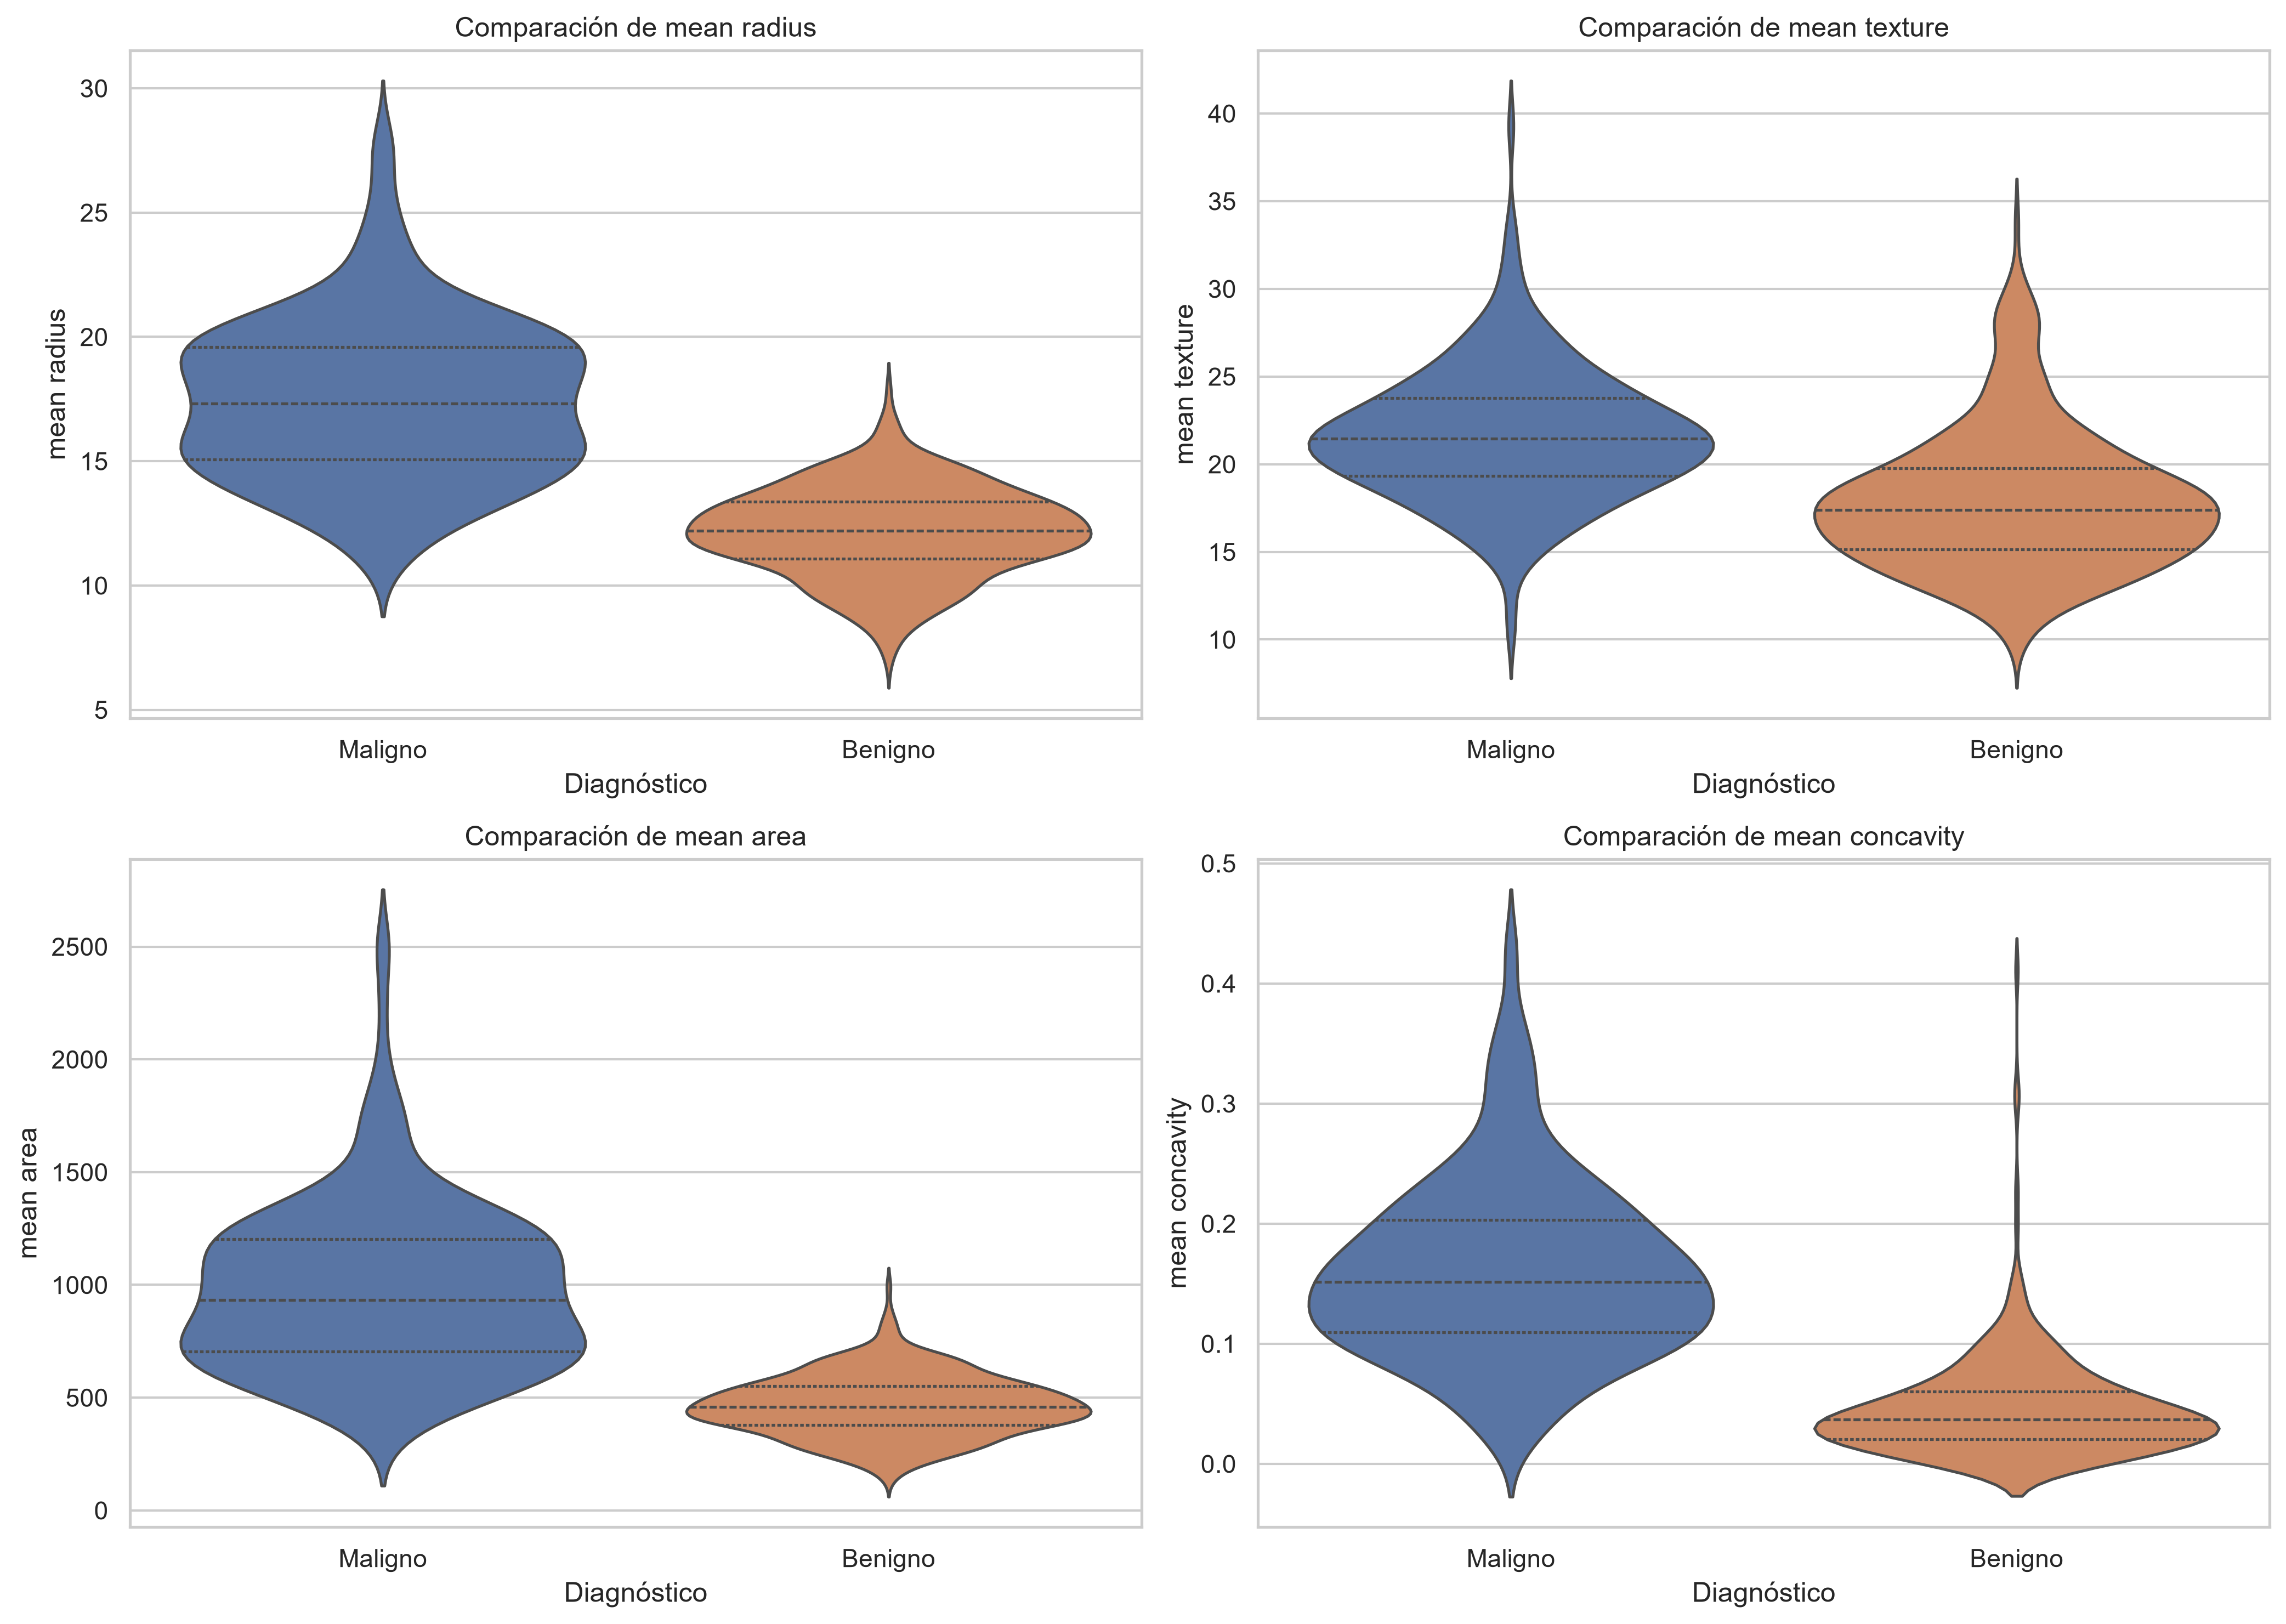


 06_correlaciones_diagnostico.png


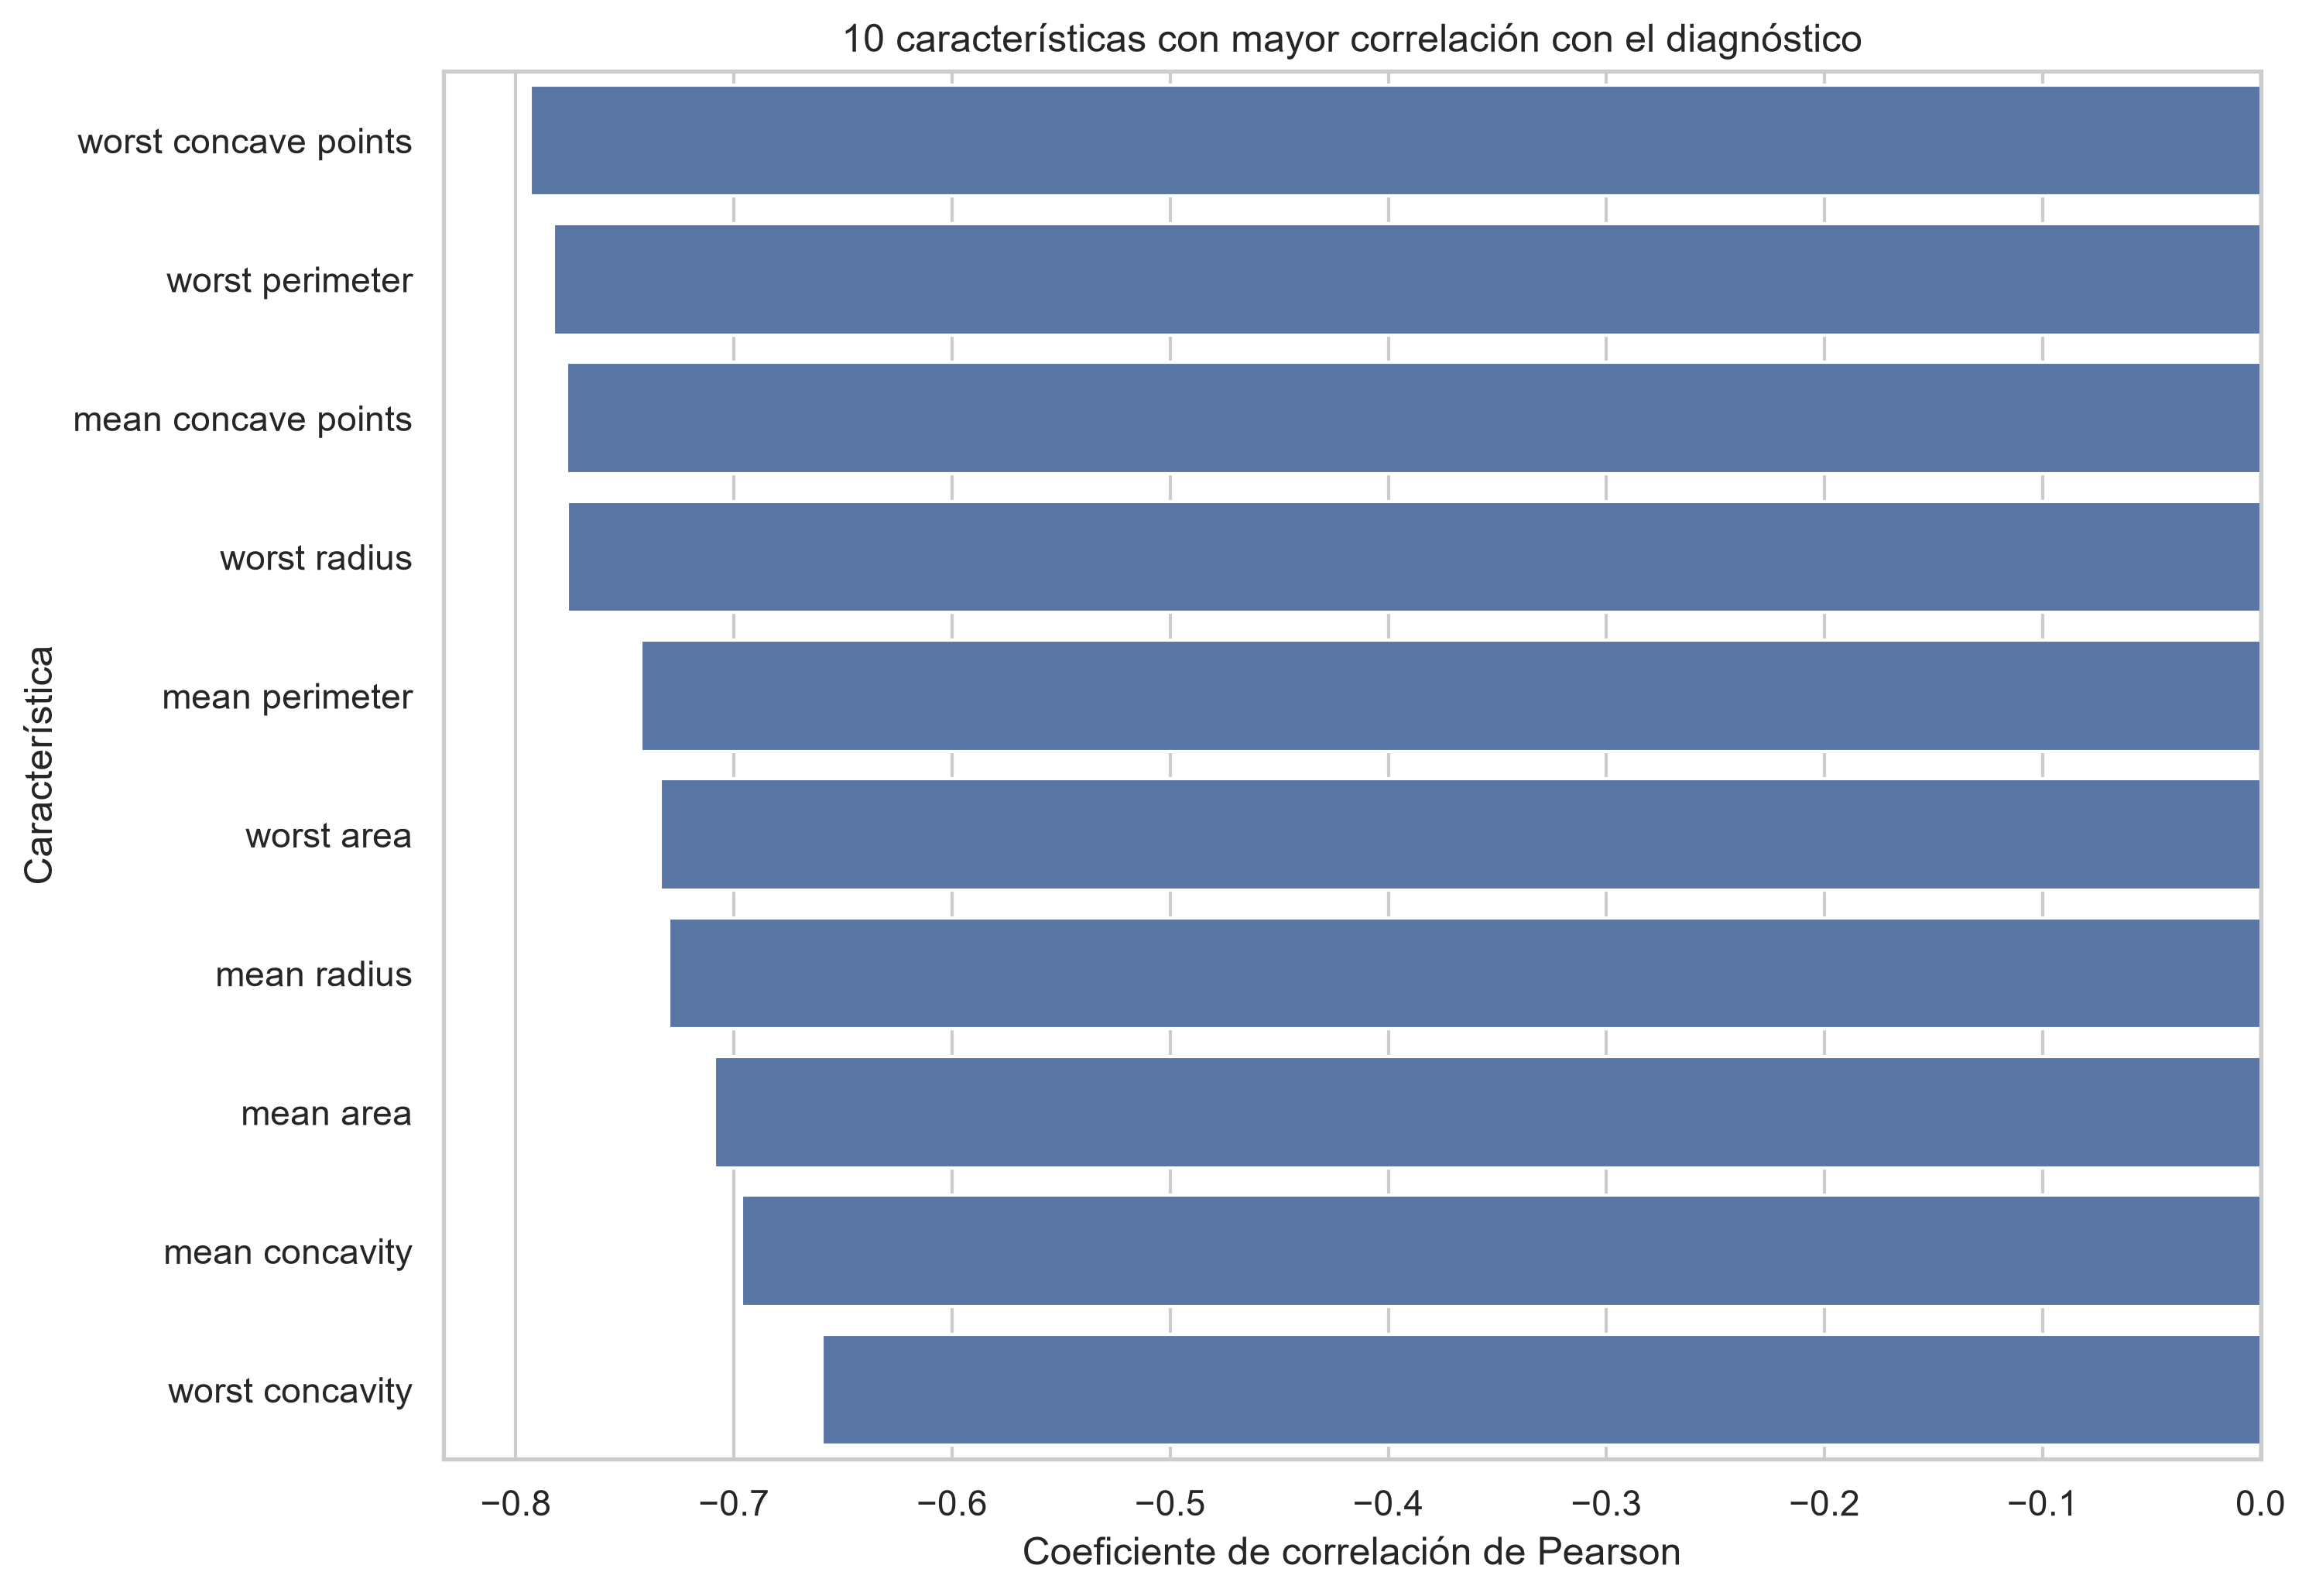

In [78]:
from IPython.display import display, Image
import os

carpeta_proyecto = os.path.dirname(os.getcwd())
carpeta_figuras = os.path.join(carpeta_proyecto, "results", "figures")

for archivo in os.listdir(carpeta_figuras):
    if archivo.endswith(".png"):
        print("\n", archivo)
        display(Image(filename=os.path.join(carpeta_figuras, archivo)))

In [79]:
import os

carpeta_proyecto = os.path.dirname(os.getcwd())
carpeta_report = os.path.join(carpeta_proyecto, "report")

os.makedirs(carpeta_report, exist_ok=True)

ruta_articulo = os.path.join(
    carpeta_report,
    "articulo_cientifico.md"
)

estructura = """
# Comparación de modelos de aprendizaje automático para la clasificación de tumores mamarios mediante el conjunto de datos Breast Cancer Wisconsin Diagnostic

**Autores:** [Nombre del autor o autores]

## Resumen

## Palabras clave

## I. Introducción

## II. Trabajos relacionados

## III. Metodología

### A. Conjunto de datos
### B. Análisis exploratorio
### C. Preprocesamiento
### D. División de los datos
### E. Modelos de clasificación
### F. Optimización de hiperparámetros
### G. Métricas de evaluación

## IV. Experimentos y resultados

### A. Resultados de validación cruzada
### B. Comparación en el conjunto de prueba
### C. Matrices de confusión
### D. Análisis de errores

## V. Discusión

## VI. Conclusiones y trabajo futuro

## Referencias
"""

with open(ruta_articulo, "w", encoding="utf-8") as archivo:
    archivo.write(estructura.strip())

print("Borrador del artículo creado correctamente.")
print("Ubicación:", ruta_articulo)

Borrador del artículo creado correctamente.
Ubicación: C:\Users\jona_\Downloads\Proyecto_Ciencia_Datos\report\articulo_cientifico.md
